In [1]:

# ============================================
# FOUR IN A ROW - AI PROJECT
# Cell 1: Imports and Configuration
# ============================================

import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets

import random
import math
import time
import pandas as pd

from IPython.display import display, clear_output

# Game configuration
ROWS = 6
COLS = 7

EMPTY = 0
PLAYER = 1
AI = 2

# AI configuration
WIN_SCORE = 100000
DEFAULT_DEPTH = 4

# Game configuration
CELL_SIZE = 1

print("Four in a Row AI Project")
print("------------------------")
print("Board size:", ROWS, "x", COLS)
print("Player:", PLAYER)
print("AI:", AI)
print("Default AI search depth:", DEFAULT_DEPTH)
print("\nLibraries imported successfully!")


Four in a Row AI Project
------------------------
Board size: 6 x 7
Player: 1
AI: 2
Default AI search depth: 4

Libraries imported successfully!


In [2]:

# ============================================
# Cell 2: Game Board and Core Game Logic
# ============================================

def create_board():
    """Create an empty 6x7 game board."""
    return np.zeros((ROWS, COLS), dtype=int)


def print_board(board):
    """Display the board in the console."""
    print(np.flip(board, 0))


def is_valid_location(board, col):
    """Check whether a column has available space."""
    return board[ROWS - 1][col] == EMPTY


def get_valid_locations(board):
    """Return all columns where a move is possible."""
    return [col for col in range(COLS)
            if is_valid_location(board, col)]


def get_next_open_row(board, col):
    """Find the lowest empty row in a column."""
    for row in range(ROWS):
        if board[row][col] == EMPTY:
            return row
    return None


def drop_piece(board, row, col, piece):
    """Place a player's disc on the board."""
    board[row][col] = piece


def winning_move(board, piece):
    """Check horizontal, vertical and diagonal wins."""

    # Horizontal
    for col in range(COLS - 3):
        for row in range(ROWS):
            if all(board[row][col + i] == piece
                   for i in range(4)):
                return True

    # Vertical
    for col in range(COLS):
        for row in range(ROWS - 3):
            if all(board[row + i][col] == piece
                   for i in range(4)):
                return True

    # Positive diagonal
    for col in range(COLS - 3):
        for row in range(ROWS - 3):
            if all(board[row + i][col + i] == piece
                   for i in range(4)):
                return True

    # Negative diagonal
    for col in range(COLS - 3):
        for row in range(3, ROWS):
            if all(board[row - i][col + i] == piece
                   for i in range(4)):
                return True

    return False


def is_draw(board):
    """Check whether the board is full."""
    return len(get_valid_locations(board)) == 0


def make_move(board, col, piece):
    """Validate and execute a move."""
    if col not in get_valid_locations(board):
        return False

    row = get_next_open_row(board, col)
    drop_piece(board, row, col, piece)

    return True


# Test the game logic
board = create_board()

make_move(board, 3, PLAYER)
make_move(board, 3, AI)
make_move(board, 2, PLAYER)
make_move(board, 4, AI)

print("Test Board:")
print_board(board)

print("\nValid columns:", get_valid_locations(board))
print("Player won:", winning_move(board, PLAYER))
print("AI won:", winning_move(board, AI))
print("Draw:", is_draw(board))


Test Board:
[[0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 2 0 0 0]
 [0 0 1 1 2 0 0]]

Valid columns: [0, 1, 2, 3, 4, 5, 6]
Player won: False
AI won: False
Draw: False


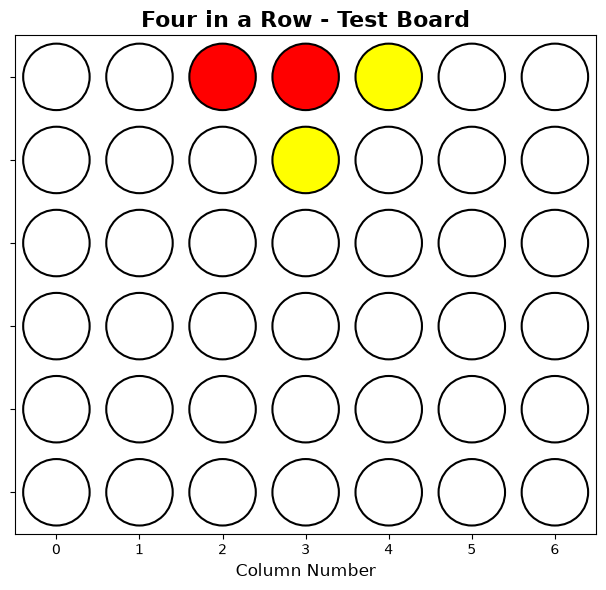

In [3]:

# ============================================
# Cell 3: Board Visualization
# ============================================

def draw_board(board, title="Four in a Row"):
    fig, ax = plt.subplots(figsize=(9, 6))

    ax.set_xlim(-0.5, COLS - 0.5)
    ax.set_ylim(-0.5, ROWS - 0.5)

    ax.set_xticks(range(COLS))
    ax.set_yticks(range(ROWS))
    ax.set_xticklabels(range(COLS))
    ax.set_yticklabels([])

    ax.set_xlabel("Column Number", fontsize=12)
    ax.set_title(title, fontsize=16, fontweight="bold")

    ax.set_facecolor("white")

    for row in range(ROWS):
        for col in range(COLS):
            if board[row][col] == PLAYER:
                color = "red"
            elif board[row][col] == AI:
                color = "yellow"
            else:
                color = "white"

            circle = plt.Circle(
                (col, row), 0.4,
                color=color,
                ec="black",
                linewidth=1.5
            )

            ax.add_patch(circle)

    ax.set_aspect("equal")
    ax.invert_yaxis()
    ax.grid(False)

    plt.tight_layout()
    plt.show()


# Test visualization
test_board = create_board()

make_move(test_board, 3, PLAYER)
make_move(test_board, 3, AI)
make_move(test_board, 2, PLAYER)
make_move(test_board, 4, AI)

draw_board(test_board, "Four in a Row - Test Board")


In [4]:

# ============================================
# Cell 4: Heuristic Evaluation
# ============================================

def evaluate_window(window, piece):
    score = 0
    opponent = PLAYER if piece == AI else AI

    # Four connected pieces
    if window.count(piece) == 4:
        score += 100

    # Three pieces and one empty space
    elif window.count(piece) == 3 and window.count(EMPTY) == 1:
        score += 10

    # Two pieces and two empty spaces
    elif window.count(piece) == 2 and window.count(EMPTY) == 2:
        score += 5

    # Opponent has three connected pieces
    if window.count(opponent) == 3 and window.count(EMPTY) == 1:
        score -= 12

    return score


def score_position(board, piece):
    score = 0

    # Prefer the center column
    center_array = list(board[:, COLS // 2])
    center_count = center_array.count(piece)
    score += center_count * 6

    # Horizontal evaluation
    for row in range(ROWS):
        for col in range(COLS - 3):
            window = list(board[row, col:col + 4])
            score += evaluate_window(window, piece)

    # Vertical evaluation
    for col in range(COLS):
        for row in range(ROWS - 3):
            window = list(board[row:row + 4, col])
            score += evaluate_window(window, piece)

    # Positive diagonal evaluation
    for row in range(ROWS - 3):
        for col in range(COLS - 3):
            window = [board[row + i][col + i]
                      for i in range(4)]
            score += evaluate_window(window, piece)

    # Negative diagonal evaluation
    for row in range(3, ROWS):
        for col in range(COLS - 3):
            window = [board[row - i][col + i]
                      for i in range(4)]
            score += evaluate_window(window, piece)

    return score


# Test heuristic
test_board = create_board()

make_move(test_board, 3, AI)
make_move(test_board, 3, AI)
make_move(test_board, 2, AI)

print("AI board score:", score_position(test_board, AI))
print("Player board score:", score_position(test_board, PLAYER))


AI board score: 37
Player board score: 0


Random AI moves:
Selected column: 5
Selected column: 4
Selected column: 2
Selected column: 3
Selected column: 6


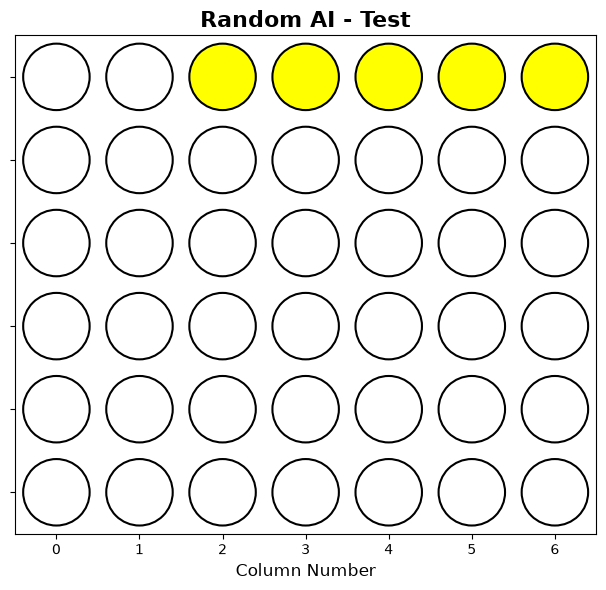

In [11]:

# ============================================
# Cell 5: Random AI
# ============================================

def random_ai_move(board):
    valid_locations = get_valid_locations(board)

    if not valid_locations:
        return None

    return random.choice(valid_locations)


# Test Random AI
test_board = create_board()

print("Random AI moves:")

for i in range(5):
    col = random_ai_move(test_board)
    make_move(test_board, col, AI)
    print("Selected column:", col)

draw_board(test_board, "Random AI - Test")


In [12]:

# ============================================
# Cell 6: Minimax Algorithm
# ============================================

def is_terminal_node(board):
    return (
        winning_move(board, PLAYER) or
        winning_move(board, AI) or
        is_draw(board)
    )


def minimax(board, depth, maximizing_player):
    valid_locations = get_valid_locations(board)
    terminal = is_terminal_node(board)

    # Terminal state or maximum search depth
    if depth == 0 or terminal:

        if terminal:
            if winning_move(board, AI):
                return (None, WIN_SCORE)
            elif winning_move(board, PLAYER):
                return (None, -WIN_SCORE)
            else:
                return (None, 0)

        return (None, score_position(board, AI))

    if maximizing_player:
        value = -math.inf
        best_col = random.choice(valid_locations)

        for col in valid_locations:
            row = get_next_open_row(board, col)

            temp_board = board.copy()
            drop_piece(temp_board, row, col, AI)

            new_score = minimax(
                temp_board, depth - 1, False
            )[1]

            if new_score > value:
                value = new_score
                best_col = col

        return best_col, value

    else:
        value = math.inf
        best_col = random.choice(valid_locations)

        for col in valid_locations:
            row = get_next_open_row(board, col)

            temp_board = board.copy()
            drop_piece(temp_board, row, col, PLAYER)

            new_score = minimax(
                temp_board, depth - 1, True
            )[1]

            if new_score < value:
                value = new_score
                best_col = col

        return best_col, value


def minimax_ai_move(board, depth=4):
    if not get_valid_locations(board):
        return None, None

    col, score = minimax(board, depth, True)

    return col, score


# Test Minimax
test_board = create_board()

make_move(test_board, 3, PLAYER)
make_move(test_board, 2, AI)
make_move(test_board, 3, PLAYER)
make_move(test_board, 4, AI)

start_time = time.time()

best_col, best_score = minimax_ai_move(
    test_board, depth=4
)

end_time = time.time()

print("Minimax AI")
print("Best column:", best_col)
print("Board evaluation:", best_score)
print("Execution time:", round(end_time - start_time, 5), "seconds")


Minimax AI
Best column: 3
Board evaluation: 16
Execution time: 0.64654 seconds


In [13]:

# ============================================
# Cell 7: Minimax with Alpha-Beta Pruning
# ============================================

# Global counter for performance analysis
nodes_explored = 0


def minimax_alpha_beta(board, depth, alpha, beta, maximizing_player):
    global nodes_explored

    nodes_explored += 1

    valid_locations = get_valid_locations(board)
    terminal = is_terminal_node(board)

    # Terminal state or maximum depth
    if depth == 0 or terminal:

        if terminal:
            if winning_move(board, AI):
                return None, WIN_SCORE
            elif winning_move(board, PLAYER):
                return None, -WIN_SCORE
            else:
                return None, 0

        return None, score_position(board, AI)

    if maximizing_player:
        value = -math.inf
        best_col = random.choice(valid_locations)

        for col in valid_locations:
            row = get_next_open_row(board, col)

            temp_board = board.copy()
            drop_piece(temp_board, row, col, AI)

            new_score = minimax_alpha_beta(
                temp_board,
                depth - 1,
                alpha,
                beta,
                False
            )[1]

            if new_score > value:
                value = new_score
                best_col = col

            alpha = max(alpha, value)

            if alpha >= beta:
                break

        return best_col, value

    else:
        value = math.inf
        best_col = random.choice(valid_locations)

        for col in valid_locations:
            row = get_next_open_row(board, col)

            temp_board = board.copy()
            drop_piece(temp_board, row, col, PLAYER)

            new_score = minimax_alpha_beta(
                temp_board,
                depth - 1,
                alpha,
                beta,
                True
            )[1]

            if new_score < value:
                value = new_score
                best_col = col

            beta = min(beta, value)

            if alpha >= beta:
                break

        return best_col, value


def alpha_beta_ai_move(board, depth=4):
    global nodes_explored

    if not get_valid_locations(board):
        return None, None

    nodes_explored = 0

    col, score = minimax_alpha_beta(
        board,
        depth,
        -math.inf,
        math.inf,
        True
    )

    return col, score


# Test Alpha-Beta Pruning
test_board = create_board()

make_move(test_board, 3, PLAYER)
make_move(test_board, 2, AI)
make_move(test_board, 3, PLAYER)
make_move(test_board, 4, AI)

start_time = time.time()

best_col, best_score = alpha_beta_ai_move(
    test_board, depth=4
)

end_time = time.time()

print("Minimax with Alpha-Beta Pruning")
print("Best column:", best_col)
print("Board evaluation:", best_score)
print("Nodes explored:", nodes_explored)
print("Execution time:", round(end_time - start_time, 5), "seconds")


Minimax with Alpha-Beta Pruning
Best column: 3
Board evaluation: 16
Nodes explored: 623
Execution time: 0.13202 seconds


In [14]:

# ============================================
# Cell 8: AI Difficulty Levels
# ============================================

DIFFICULTY_LEVELS = {
    "Easy": {
        "algorithm": "Random",
        "depth": 0
    },
    "Medium": {
        "algorithm": "Minimax",
        "depth": 2
    },
    "Hard": {
        "algorithm": "Alpha-Beta",
        "depth": 4
    },
    "Expert": {
        "algorithm": "Alpha-Beta",
        "depth": 6
    }
}


def get_ai_move(board, difficulty="Hard"):
    settings = DIFFICULTY_LEVELS[difficulty]

    algorithm = settings["algorithm"]
    depth = settings["depth"]

    start_time = time.time()

    if algorithm == "Random":
        col = random_ai_move(board)
        score = score_position(board, AI)

    elif algorithm == "Minimax":
        col, score = minimax_ai_move(board, depth)

    else:
        col, score = alpha_beta_ai_move(board, depth)

    execution_time = time.time() - start_time

    return {
        "column": col,
        "score": score,
        "algorithm": algorithm,
        "depth": depth,
        "time": execution_time
    }


# Test all difficulty levels
test_board = create_board()

make_move(test_board, 3, PLAYER)
make_move(test_board, 2, AI)
make_move(test_board, 3, PLAYER)

for level in DIFFICULTY_LEVELS:
    result = get_ai_move(test_board, level)

    print("\nDifficulty:", level)
    print("Algorithm:", result["algorithm"])
    print("Selected column:", result["column"])
    print("Score:", result["score"])
    print("Time:", round(result["time"], 5), "seconds")



Difficulty: Easy
Algorithm: Random
Selected column: 4
Score: 0
Time: 0.001 seconds

Difficulty: Medium
Algorithm: Minimax
Selected column: 3
Score: 6
Time: 0.01699 seconds

Difficulty: Hard
Algorithm: Alpha-Beta
Selected column: 3
Score: 6
Time: 0.15102 seconds

Difficulty: Expert
Algorithm: Alpha-Beta
Selected column: 3
Score: 12
Time: 2.33345 seconds


In [ ]:

# ============================================
# Cell 9: Interactive Human vs AI Game
# ============================================

game_board = create_board()
game_over = False
human_turn = True
game_difficulty = "Hard"

game_output = widgets.Output()

difficulty_dropdown = widgets.Dropdown(
    options=["Easy", "Medium", "Hard", "Expert"],
    value="Hard",
    description="Difficulty:"
)

status_label = widgets.HTML(
    value="<h3 style='color:green'>Your Turn (Red)</h3>"
)

info_label = widgets.HTML(value="")

column_buttons = [
    widgets.Button(
        description=str(col),
        button_style="primary",
        layout=widgets.Layout(width="65px", height="35px")
    )
    for col in range(COLS)
]

restart_button = widgets.Button(
    description="Restart Game",
    button_style="success",
    icon="refresh"
)


def render_game():
    with game_output:
        clear_output(wait=True)
        draw_board(game_board, "Four in a Row - Human vs AI")


def update_status(message, color="black"):
    status_label.value = (
        f"<h3 style='color:{color}'>{message}</h3>"
    )


def finish_game(message, color):
    global game_over
    game_over = True
    update_status(message, color)

    for button in column_buttons:
        button.disabled = True


def human_move(col):
    global human_turn

    if game_over or not human_turn:
        return

    if not is_valid_location(game_board, col):
        update_status("Column is full! Choose another.", "red")
        return

    make_move(game_board, col, PLAYER)
    render_game()

    if winning_move(game_board, PLAYER):
        finish_game("Congratulations! You Won!", "green")
        return

    if is_draw(game_board):
        finish_game("Game Draw!", "orange")
        return

    human_turn = False
    for button in column_buttons:
        button.disabled = True

    update_status("AI is thinking...", "blue")

    with game_output:
        print("AI is calculating its next move...")


    result = get_ai_move(game_board, game_difficulty)
    ai_col = result["column"]

    if ai_col is not None:
        make_move(game_board, ai_col, AI)

    render_game()

    info_label.value = (
        f"<b>AI Algorithm:</b> {result['algorithm']} | "
        f"<b>Depth:</b> {result['depth']} | "
        f"<b>Column:</b> {ai_col} | "
        f"<b>Score:</b> {result['score']} | "
        f"<b>Time:</b> {result['time']:.4f}s"
    )

    if winning_move(game_board, AI):
        finish_game("AI Wins! Better Luck Next Time.", "red")
        return

    if is_draw(game_board):
        finish_game("Game Draw!", "orange")
        return

    human_turn = True
    for button in column_buttons:
        button.disabled = False

    update_status("Your Turn (Red)", "green")


def restart_game(button=None):
    global game_board, game_over, human_turn, game_difficulty

    game_board = create_board()
    game_over = False
    human_turn = True

    game_difficulty = difficulty_dropdown.value

    for button in column_buttons:
        button.disabled = False

    info_label.value = ""
    update_status("Your Turn (Red)", "green")

    render_game()


def change_difficulty(change):
    global game_difficulty

    game_difficulty = change["new"]


for col in range(COLS):
    column_buttons[col].on_click(
        lambda button, c=col: human_move(c)
    )

difficulty_dropdown.observe(
    change_difficulty,
    names="value"
)

restart_button.on_click(restart_game)

game_controls = widgets.HBox(column_buttons)

game_interface = widgets.VBox([
    widgets.HTML("<h2>Four in a Row - Human vs AI</h2>"),
    difficulty_dropdown,
    status_label,
    game_controls,
    game_output,
    info_label,
    restart_button
])

display(game_interface)

restart_game()


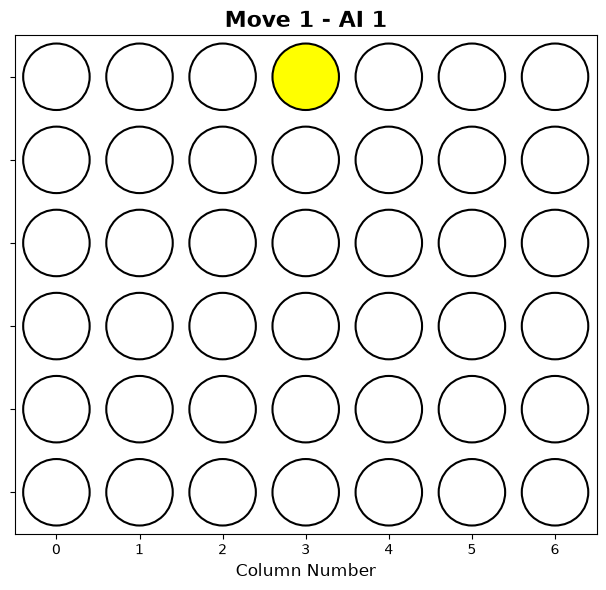

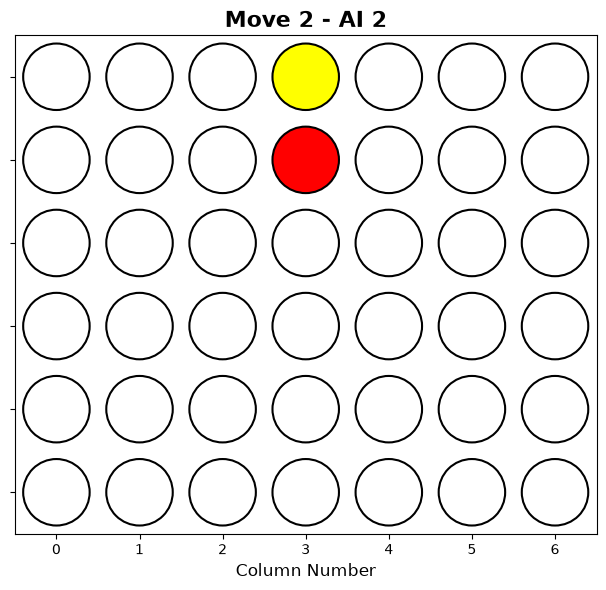

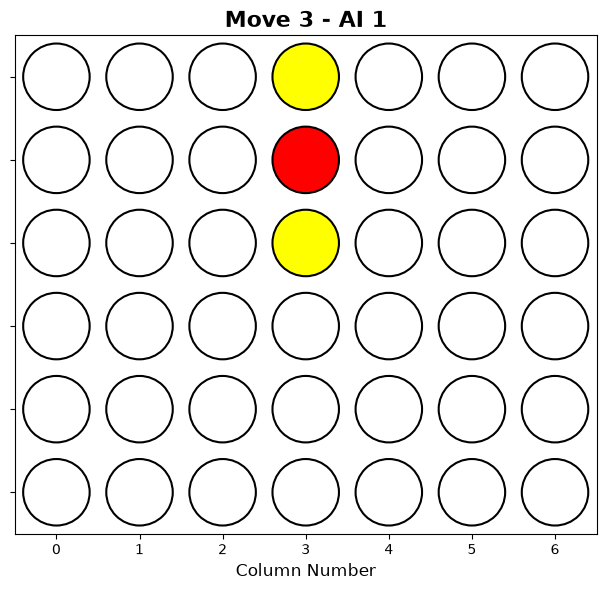

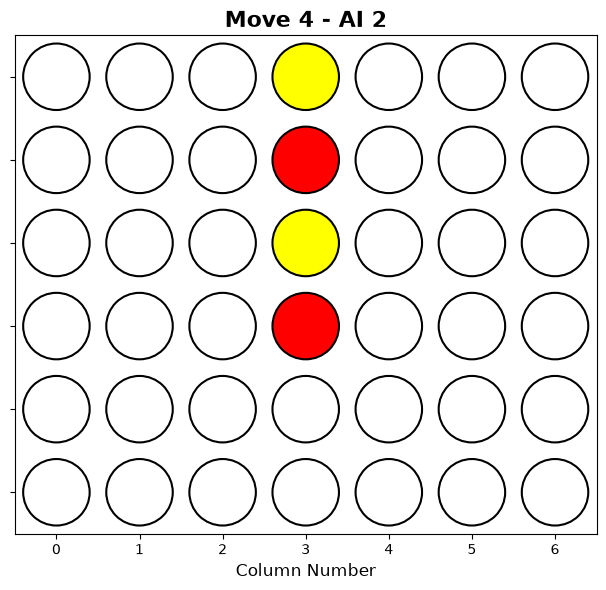

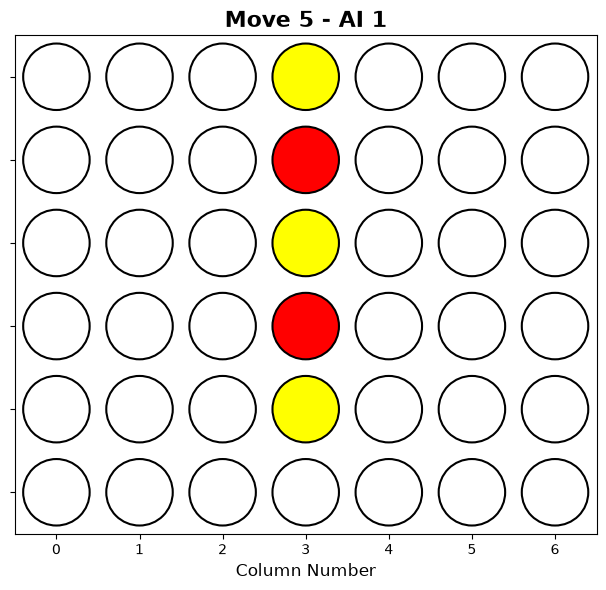

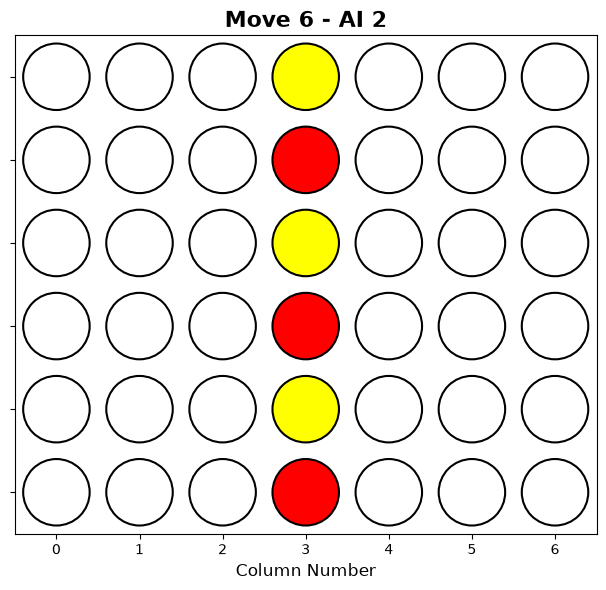

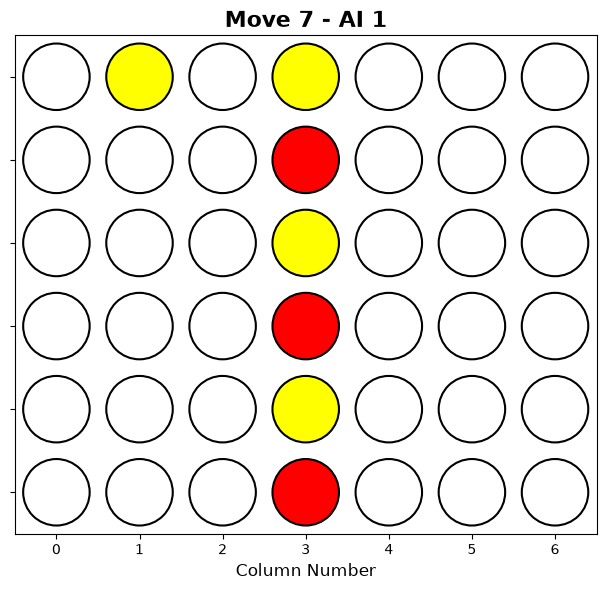

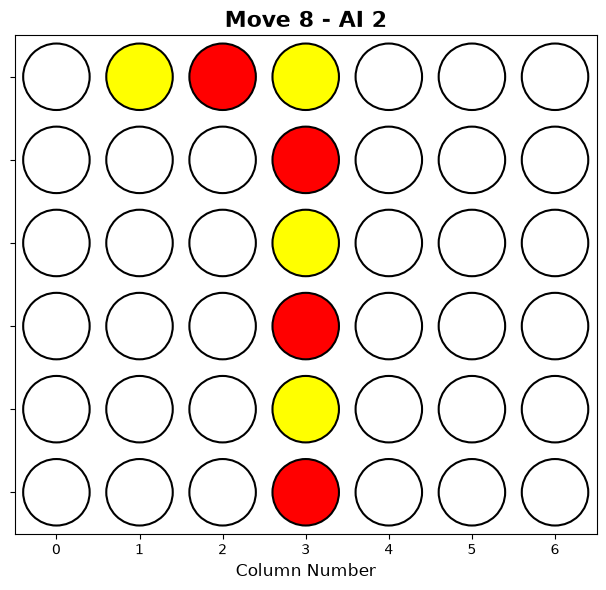

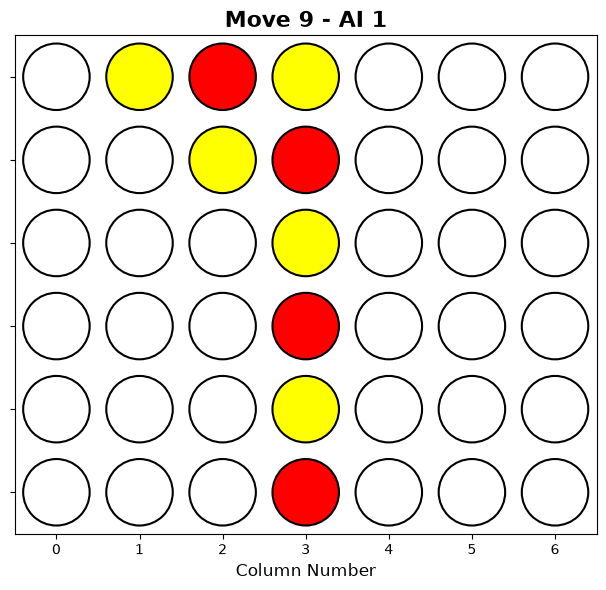

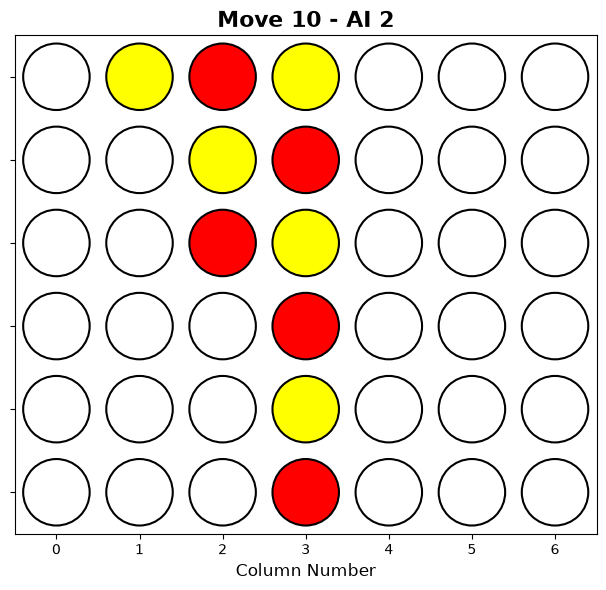

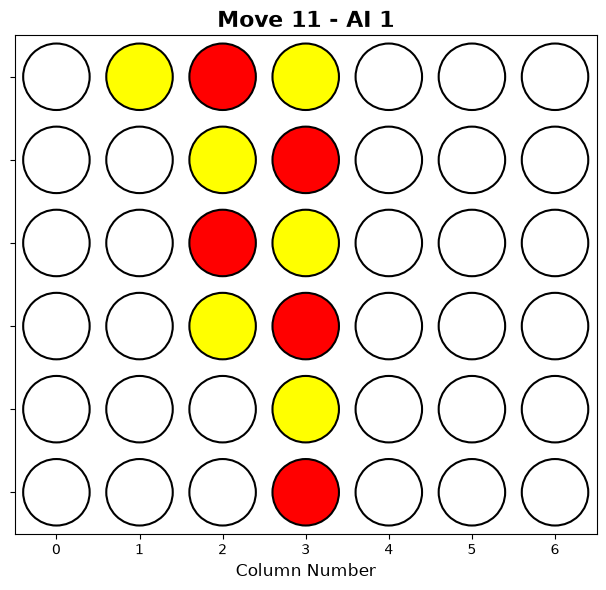

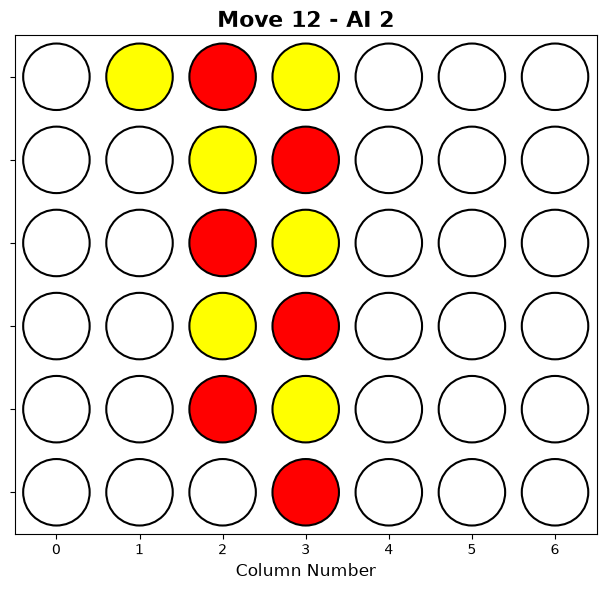

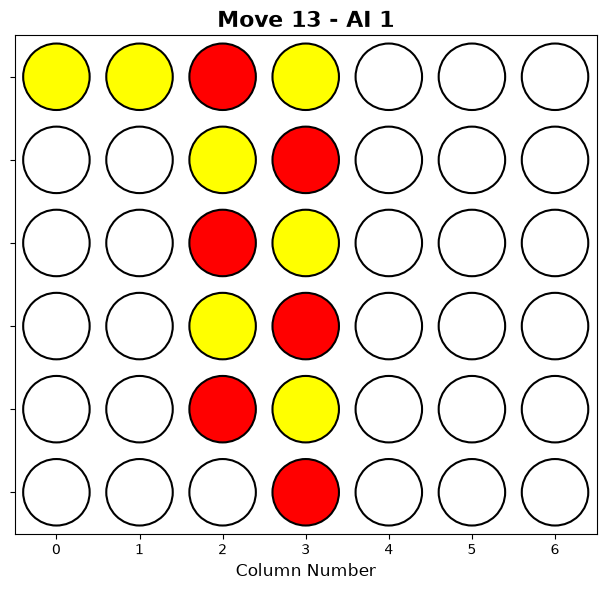

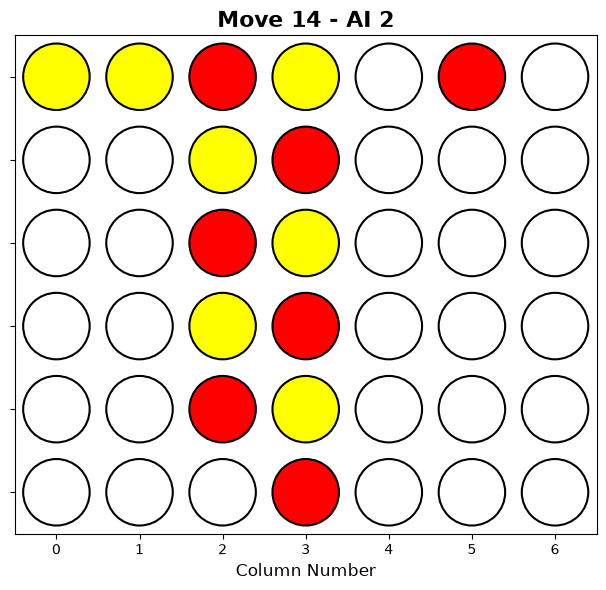

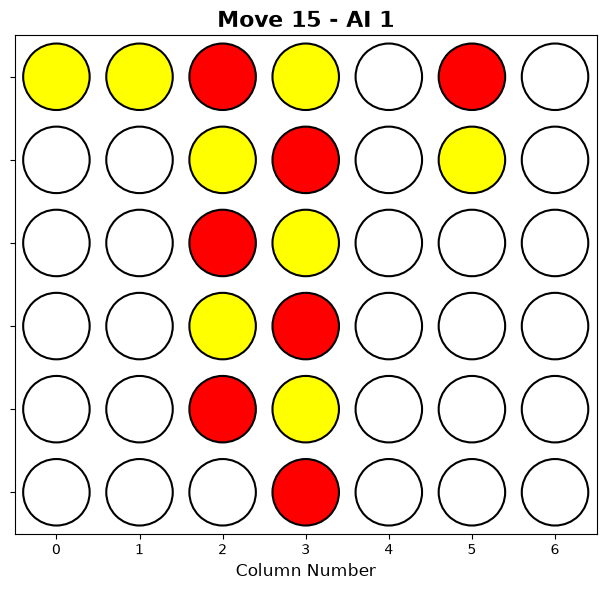

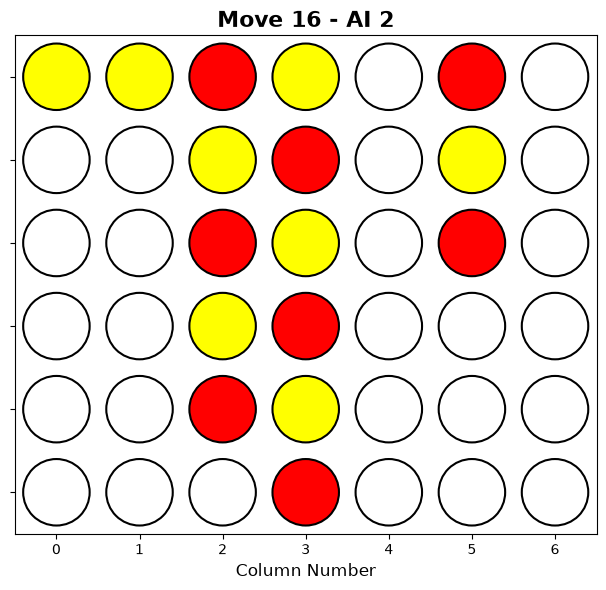

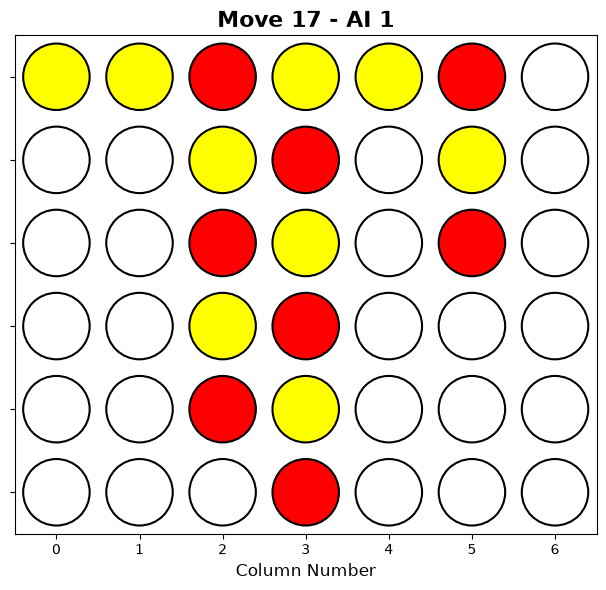

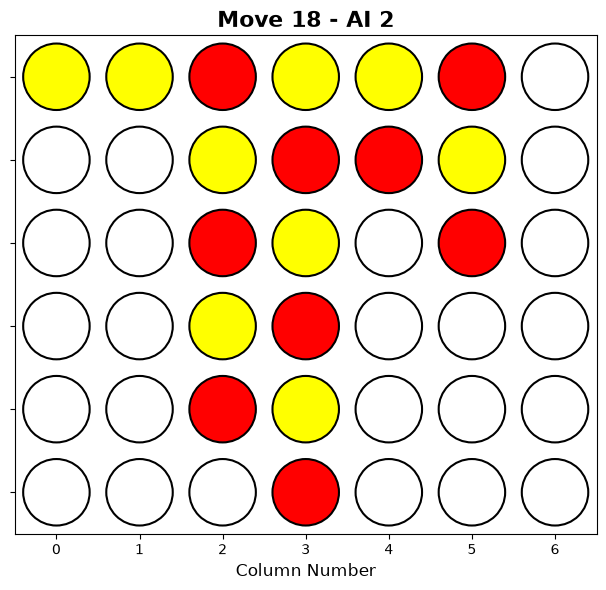

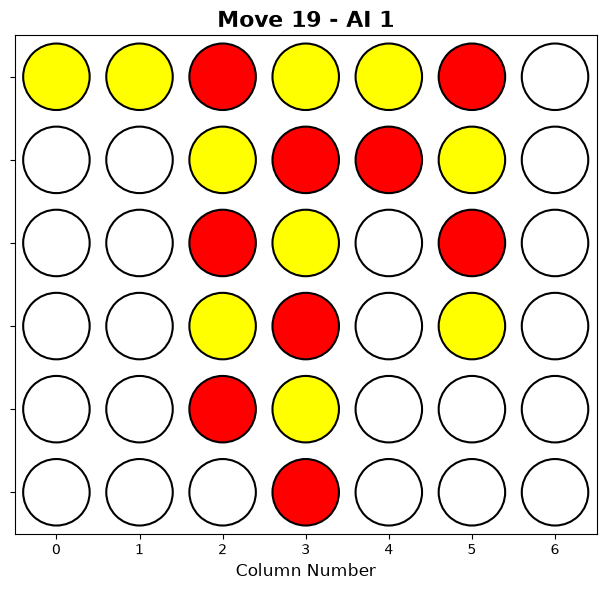

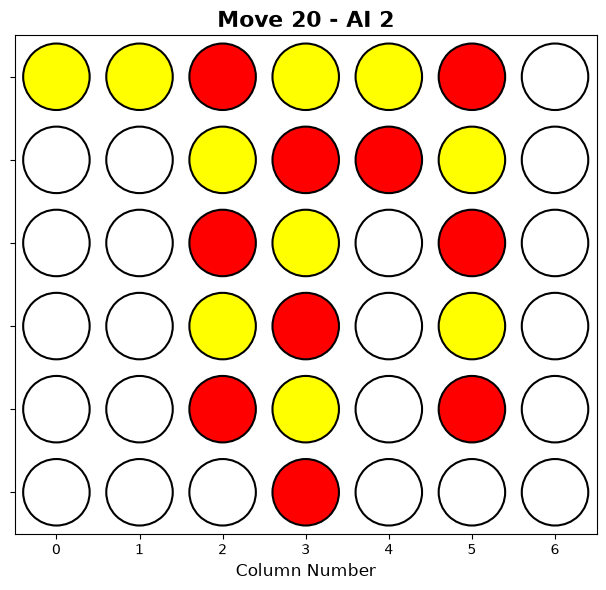

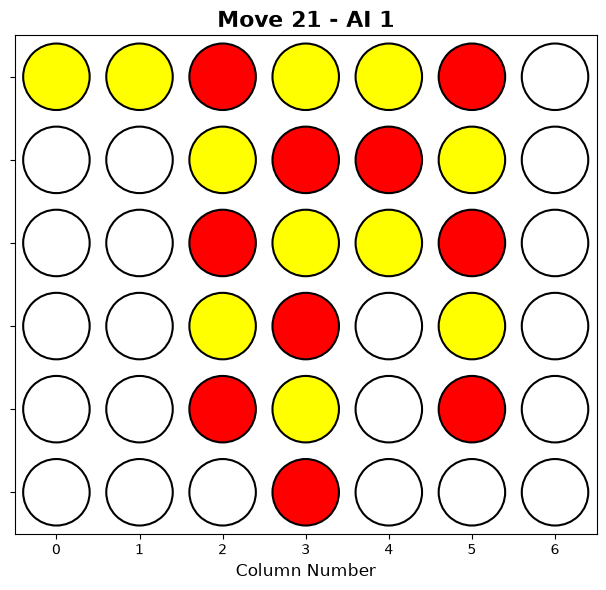

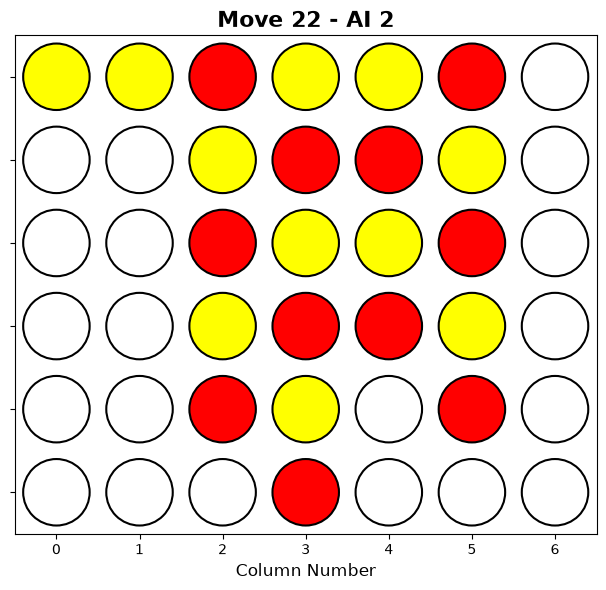

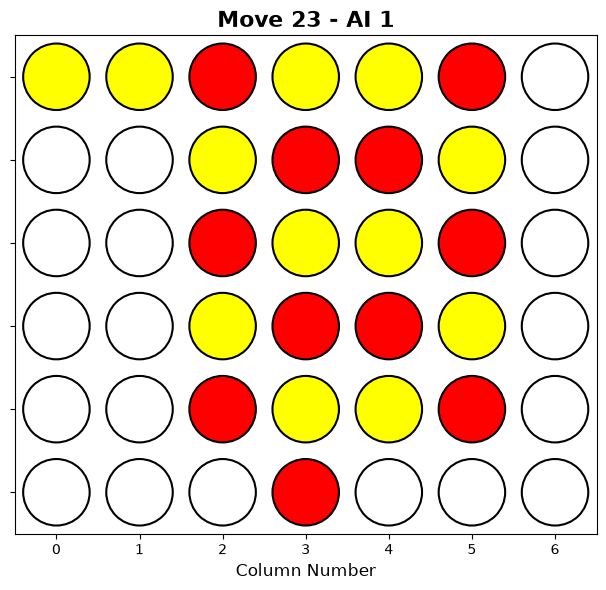

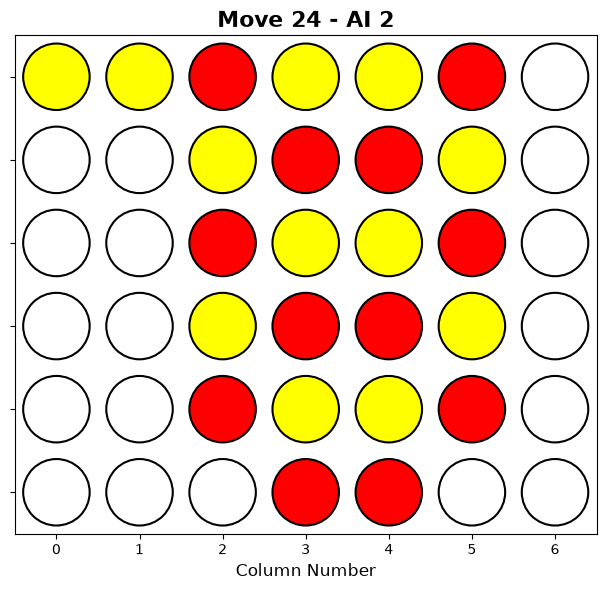

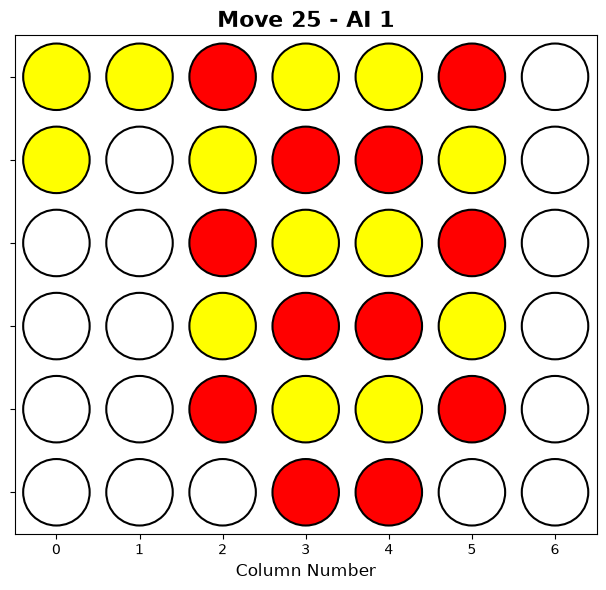

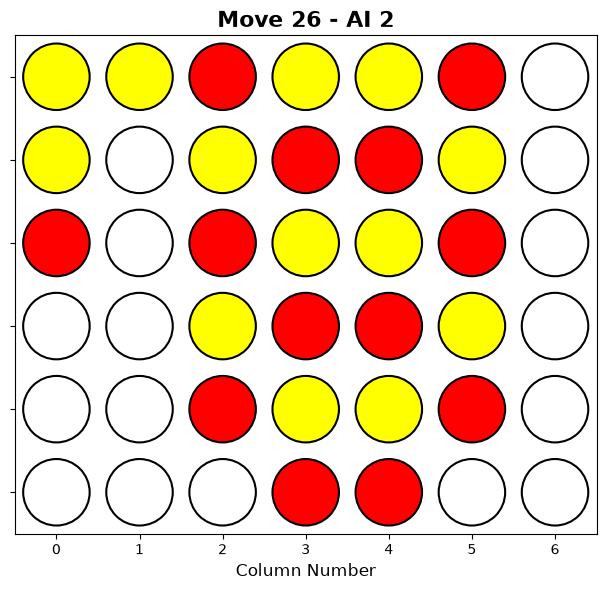

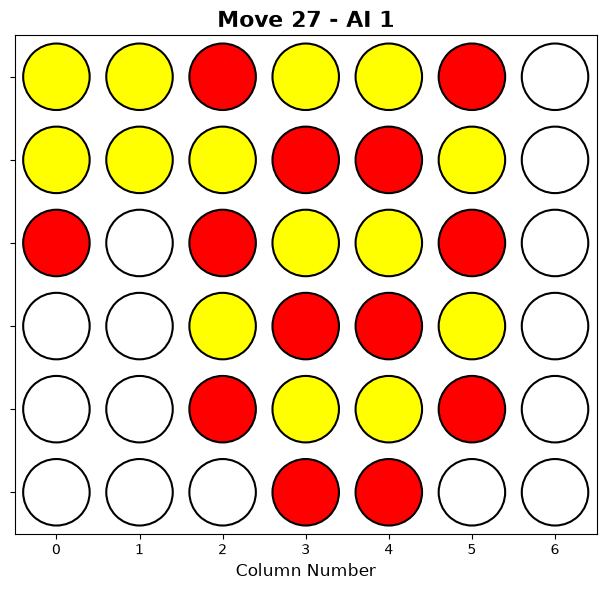

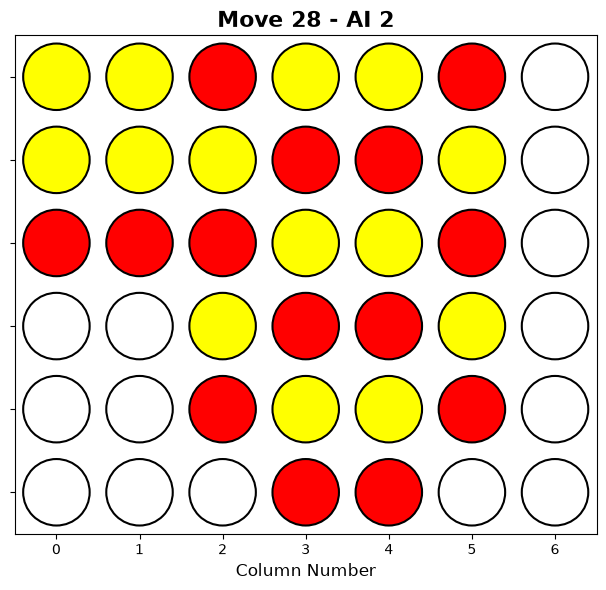

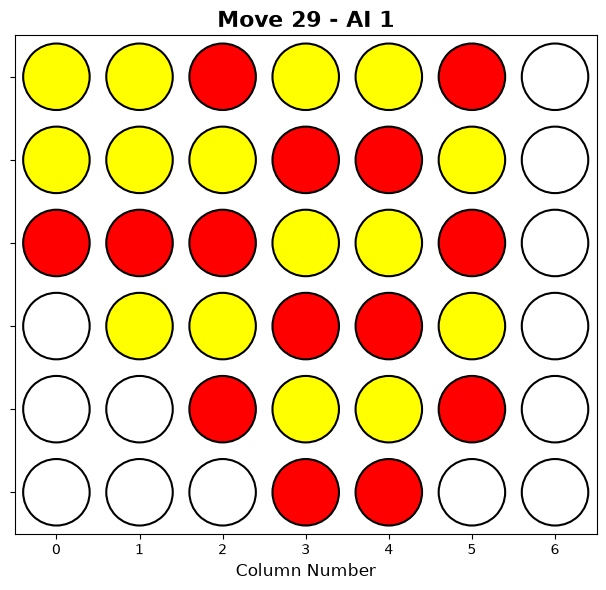

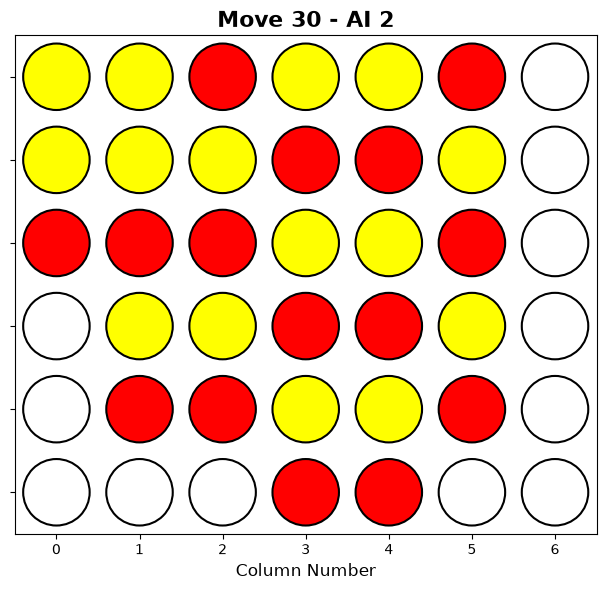

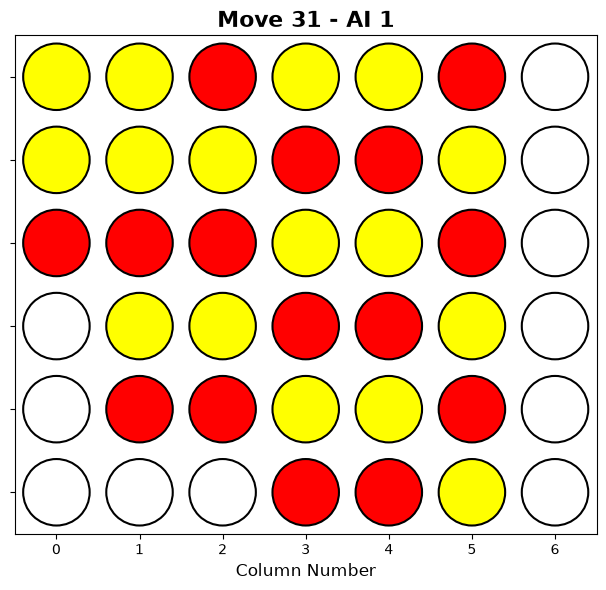

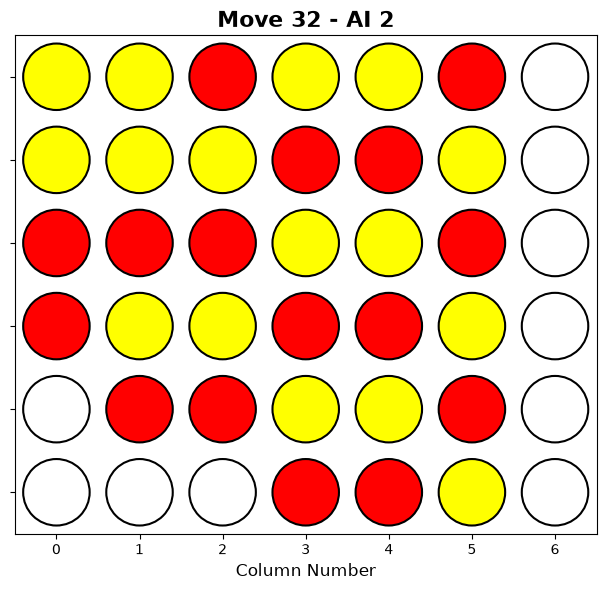

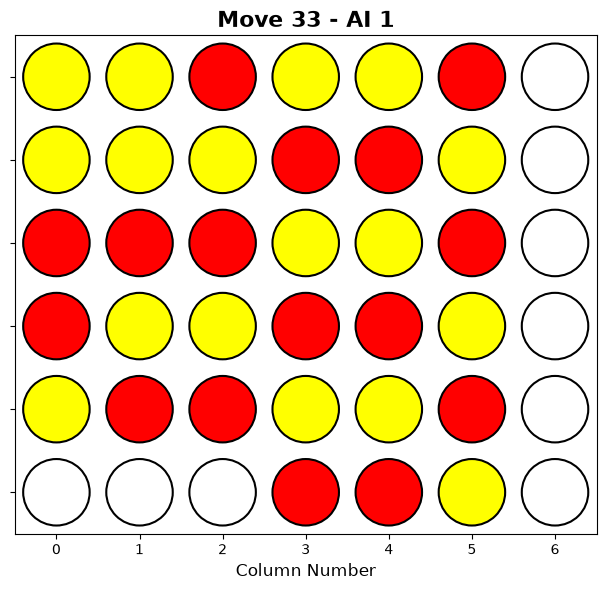

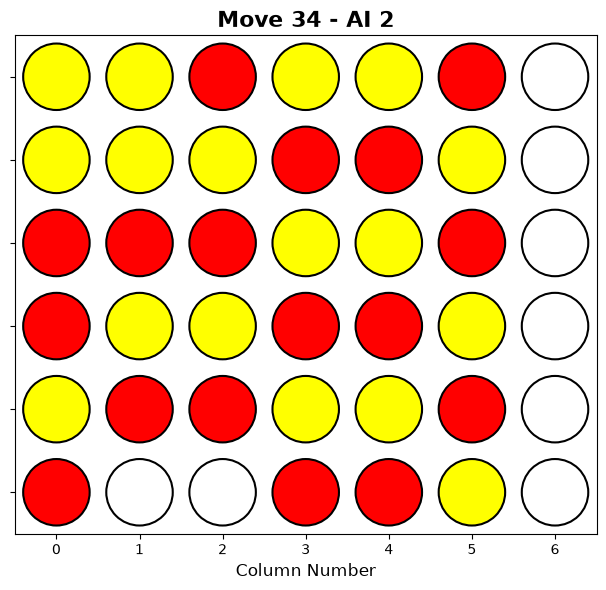

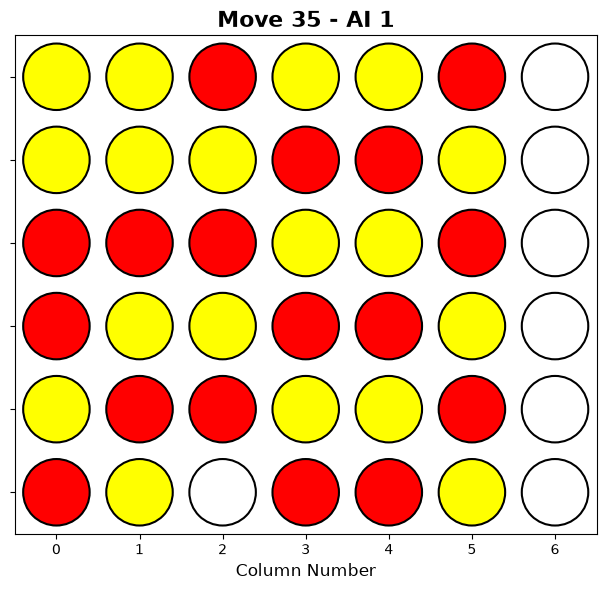

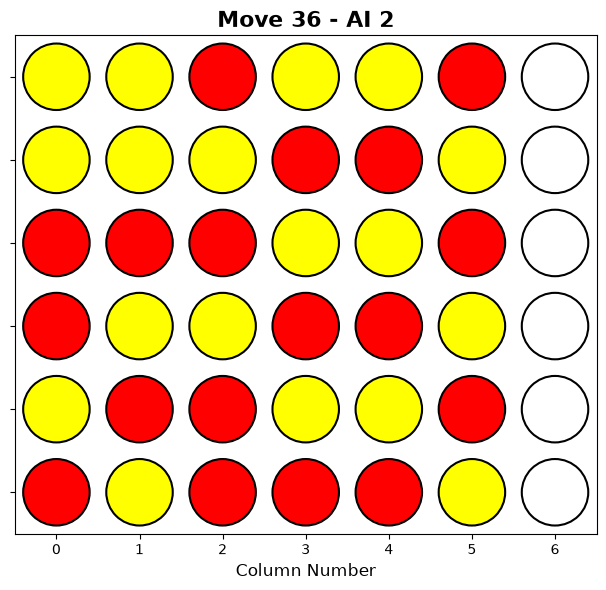

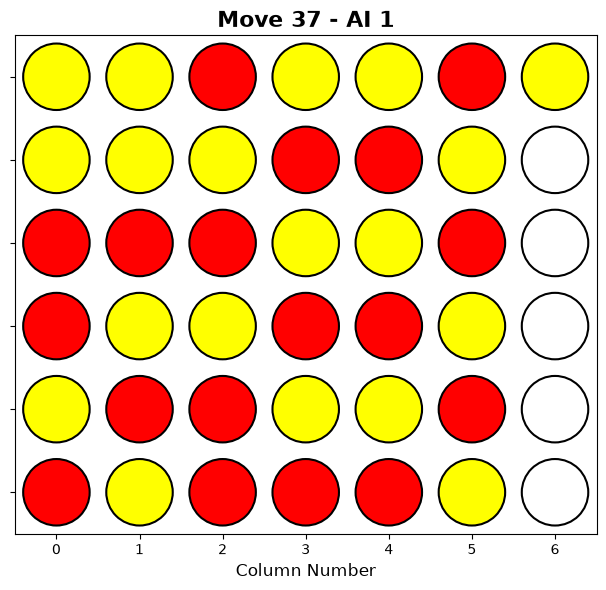

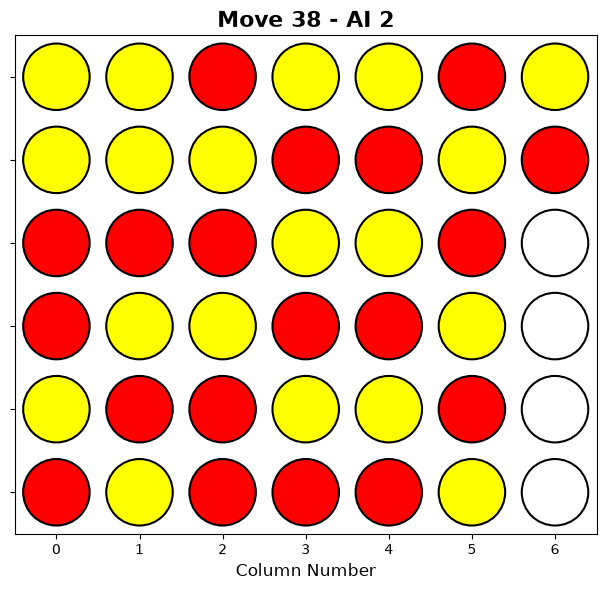

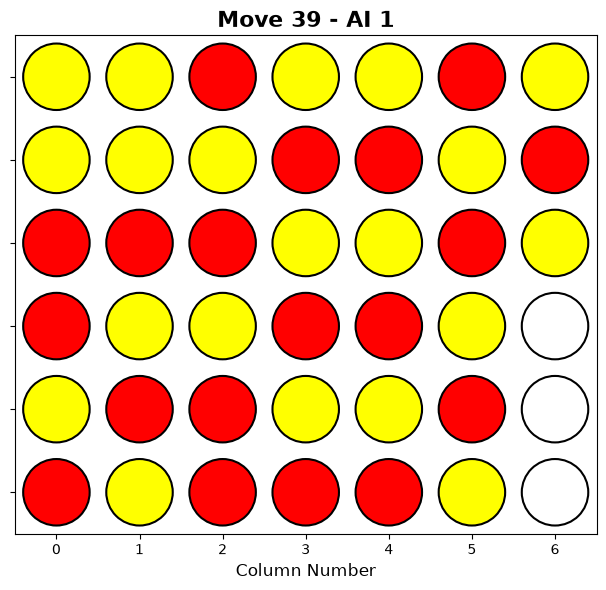

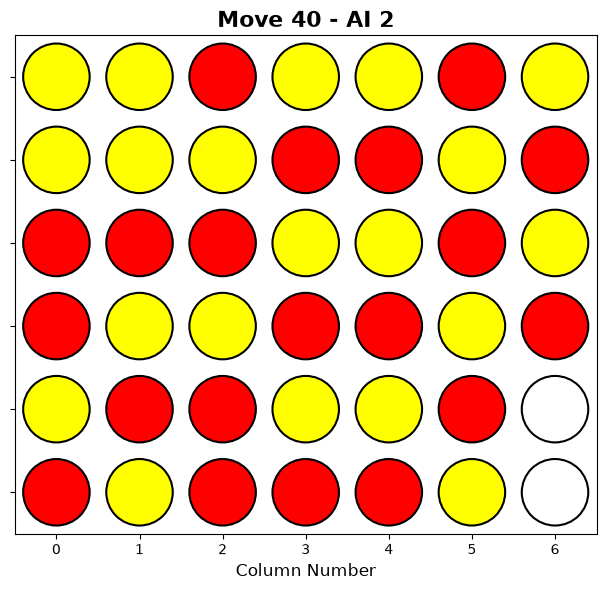

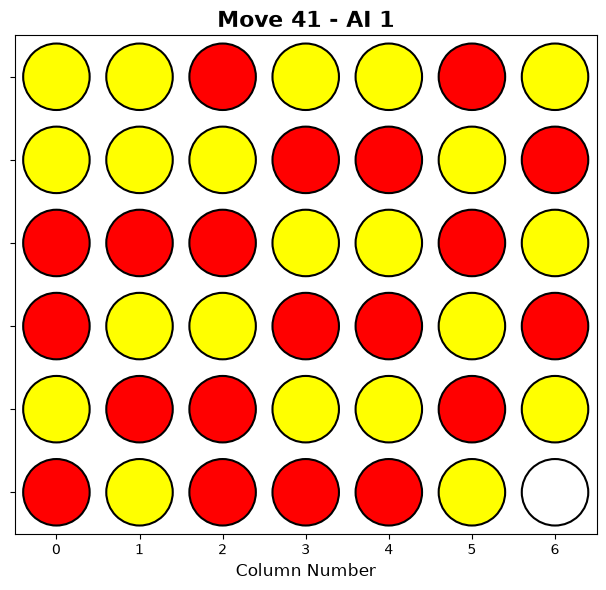

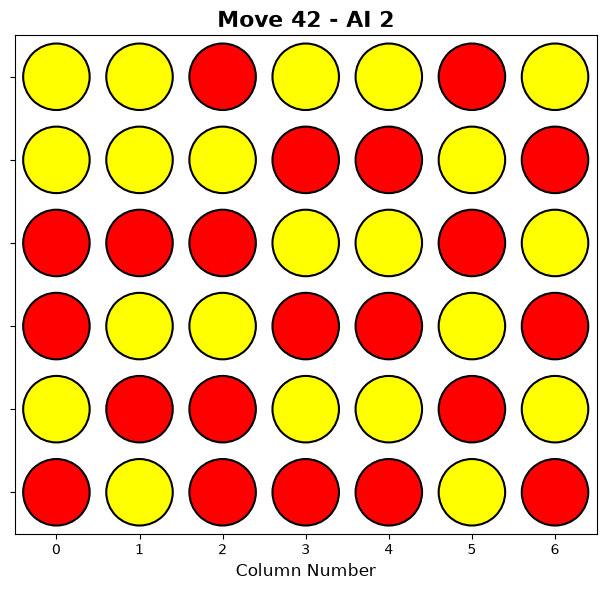

Game Result: Draw
Total moves: 42

Final Result: {'winner': 'Draw', 'moves': 42, 'ai1_nodes': 0, 'ai2_nodes': 1721}


In [16]:

# ============================================
# Cell 10: AI vs AI Mode
# ============================================

def play_ai_game(ai1="Minimax", ai2="Alpha-Beta",
                 depth1=4, depth2=4, show_game=True):

    board = create_board()
    current_player = AI
    move_count = 0

    ai1_nodes = 0
    ai2_nodes = 0

    while not is_terminal_node(board):

        if current_player == AI:

            if ai1 == "Random":
                col = random_ai_move(board)

            elif ai1 == "Minimax":
                col, _ = minimax_ai_move(board, depth1)

            else:
                col, _ = alpha_beta_ai_move(board, depth1)
                ai1_nodes += nodes_explored

        else:

            if ai2 == "Random":
                col = random_ai_move(board)

            elif ai2 == "Minimax":
                col, _ = minimax_ai_move(board, depth2)

            else:
                col, _ = alpha_beta_ai_move(board, depth2)
                ai2_nodes += nodes_explored

        if col is None:
            break

        make_move(board, col, current_player)
        move_count += 1

        if show_game:
            draw_board(
                board,
                f"Move {move_count} - "
                f"{'AI 1' if current_player == AI else 'AI 2'}"
            )

        if winning_move(board, current_player):
            winner = "AI 1" if current_player == AI else "AI 2"
            break

        current_player = PLAYER if current_player == AI else AI

    else:
        winner = "Draw"

    if show_game:
        print("Game Result:", winner)
        print("Total moves:", move_count)

    return {
        "winner": winner,
        "moves": move_count,
        "ai1_nodes": ai1_nodes,
        "ai2_nodes": ai2_nodes
    }


# Test AI vs AI
result = play_ai_game(
    ai1="Minimax",
    ai2="Alpha-Beta",
    depth1=3,
    depth2=3,
    show_game=True
)

print("\nFinal Result:", result)


In [21]:

# ============================================
# Cell 11: AI Algorithms with Performance Counting
# ============================================

def swap_perspective(board):
    """Swap AI and Player pieces for symmetric AI evaluation."""
    swapped = board.copy()
    swapped[board == AI] = PLAYER
    swapped[board == PLAYER] = AI
    return swapped


def minimax_counted(board, depth, maximizing_player, counter):
    counter[0] += 1

    valid_locations = get_valid_locations(board)
    terminal = is_terminal_node(board)

    if depth == 0 or terminal:
        if terminal:
            if winning_move(board, AI):
                return None, WIN_SCORE
            elif winning_move(board, PLAYER):
                return None, -WIN_SCORE
            return None, 0

        return None, score_position(board, AI)

    if maximizing_player:
        value = -math.inf
        best_col = random.choice(valid_locations)

        for col in valid_locations:
            row = get_next_open_row(board, col)
            temp_board = board.copy()
            drop_piece(temp_board, row, col, AI)

            new_score = minimax_counted(
                temp_board, depth - 1, False, counter
            )[1]

            if new_score > value:
                value = new_score
                best_col = col

        return best_col, value

    else:
        value = math.inf
        best_col = random.choice(valid_locations)

        for col in valid_locations:
            row = get_next_open_row(board, col)
            temp_board = board.copy()
            drop_piece(temp_board, row, col, PLAYER)

            new_score = minimax_counted(
                temp_board, depth - 1, True, counter
            )[1]

            if new_score < value:
                value = new_score
                best_col = col

        return best_col, value


def alphabeta_counted(board, depth, alpha, beta,
                      maximizing_player, counter):
    counter[0] += 1

    valid_locations = get_valid_locations(board)
    terminal = is_terminal_node(board)

    if depth == 0 or terminal:
        if terminal:
            if winning_move(board, AI):
                return None, WIN_SCORE
            elif winning_move(board, PLAYER):
                return None, -WIN_SCORE
            return None, 0

        return None, score_position(board, AI)

    if maximizing_player:
        value = -math.inf
        best_col = random.choice(valid_locations)

        for col in valid_locations:
            row = get_next_open_row(board, col)
            temp_board = board.copy()
            drop_piece(temp_board, row, col, AI)

            new_score = alphabeta_counted(
                temp_board, depth - 1,
                alpha, beta, False, counter
            )[1]

            if new_score > value:
                value = new_score
                best_col = col

            alpha = max(alpha, value)

            if alpha >= beta:
                break

        return best_col, value

    else:
        value = math.inf
        best_col = random.choice(valid_locations)

        for col in valid_locations:
            row = get_next_open_row(board, col)
            temp_board = board.copy()
            drop_piece(temp_board, row, col, PLAYER)

            new_score = alphabeta_counted(
                temp_board, depth - 1,
                alpha, beta, True, counter
            )[1]

            if new_score < value:
                value = new_score
                best_col = col

            beta = min(beta, value)

            if alpha >= beta:
                break

        return best_col, value


def get_experimental_move(board, piece, algorithm, depth=4):
    """Get a move from any AI algorithm for either player."""

    # Normalize the board so the current agent is always AI.
    normalized_board = (
        board.copy() if piece == AI
        else swap_perspective(board)
    )

    counter = [0]
    start = time.perf_counter()

    if algorithm == "Random":
        col = random_ai_move(normalized_board)
        score = score_position(normalized_board, AI)

    elif algorithm == "Minimax":
        col, score = minimax_counted(
            normalized_board, depth, True, counter
        )

    elif algorithm == "Alpha-Beta":
        col, score = alphabeta_counted(
            normalized_board, depth,
            -math.inf, math.inf, True, counter
        )

    else:
        raise ValueError("Unknown AI algorithm")

    elapsed = time.perf_counter() - start

    return {
        "column": col,
        "score": score,
        "nodes": counter[0],
        "time": elapsed
    }


# Test the instrumented algorithms
test_board = create_board()

make_move(test_board, 3, PLAYER)
make_move(test_board, 2, AI)
make_move(test_board, 3, PLAYER)

for algorithm in ["Minimax", "Alpha-Beta"]:
    result = get_experimental_move(
        test_board, AI, algorithm, depth=4
    )

    print("\nAlgorithm:", algorithm)
    print("Selected column:", result["column"])
    print("Evaluation score:", result["score"])
    print("Nodes explored:", result["nodes"])
    print("Execution time:", round(result["time"], 6), "seconds")



Algorithm: Minimax
Selected column: 3
Evaluation score: 6
Nodes explored: 2801
Execution time: 0.551909 seconds

Algorithm: Alpha-Beta
Selected column: 3
Evaluation score: 6
Nodes explored: 725
Execution time: 0.138973 seconds


In [22]:

# ============================================
# Cell 12: Automated AI Tournament
# ============================================

def play_experimental_game(
    algorithm1,
    algorithm2,
    depth1=4,
    depth2=4,
    first_player=AI
):
    board = create_board()
    current_player = first_player

    stats = {
        algorithm1: {"time": [], "nodes": []},
        algorithm2: {"time": [], "nodes": []}
    }

    while not is_terminal_node(board):

        if current_player == AI:
            algorithm = algorithm1
            depth = depth1
        else:
            algorithm = algorithm2
            depth = depth2

        result = get_experimental_move(
            board, current_player, algorithm, depth
        )

        col = result["column"]

        if col is None:
            break

        stats[algorithm]["time"].append(result["time"])
        stats[algorithm]["nodes"].append(result["nodes"])

        make_move(board, col, current_player)

        if winning_move(board, current_player):
            winner = algorithm
            break

        current_player = (
            PLAYER if current_player == AI else AI
        )

    else:
        winner = "Draw"

    return winner, stats


def run_tournament(games_per_pair=20, depth=4):

    algorithms = ["Random", "Minimax", "Alpha-Beta"]

    records = []

    for i in range(len(algorithms)):
        for j in range(i + 1, len(algorithms)):

            algorithm1 = algorithms[i]
            algorithm2 = algorithms[j]

            print(f"\n{algorithm1} vs {algorithm2}")

            for game in range(games_per_pair):

                # Alternate who moves first.
                first_player = AI if game % 2 == 0 else PLAYER

                winner, stats = play_experimental_game(
                    algorithm1,
                    algorithm2,
                    depth,
                    depth,
                    first_player
                )

                for algorithm in [algorithm1, algorithm2]:

                    if winner == "Draw":
                        outcome = "Draw"
                    elif winner == algorithm:
                        outcome = "Win"
                    else:
                        outcome = "Loss"

                    times = stats[algorithm]["time"]
                    nodes = stats[algorithm]["nodes"]

                    records.append({
                        "Algorithm": algorithm,
                        "Opponent": (
                            algorithm2 if algorithm == algorithm1
                            else algorithm1
                        ),
                        "Outcome": outcome,
                        "Average Time": np.mean(times) if times else 0,
                        "Average Nodes": np.mean(nodes) if nodes else 0
                    })

                print(
                    f"Game {game + 1}/{games_per_pair}: {winner}"
                )

    return pd.DataFrame(records)


# Run the tournament
tournament_df = run_tournament(
    games_per_pair=20,
    depth=4
)

print("\nTournament completed!")
print("Total recorded agent performances:", len(tournament_df))

display(tournament_df.head(10))



Random vs Minimax
Game 1/20: Minimax
Game 2/20: Minimax
Game 3/20: Minimax
Game 4/20: Minimax
Game 5/20: Minimax
Game 6/20: Minimax
Game 7/20: Minimax
Game 8/20: Minimax
Game 9/20: Minimax
Game 10/20: Minimax
Game 11/20: Minimax
Game 12/20: Minimax
Game 13/20: Minimax
Game 14/20: Minimax
Game 15/20: Minimax
Game 16/20: Minimax
Game 17/20: Minimax
Game 18/20: Minimax
Game 19/20: Minimax
Game 20/20: Minimax

Random vs Alpha-Beta
Game 1/20: Alpha-Beta
Game 2/20: Alpha-Beta
Game 3/20: Alpha-Beta
Game 4/20: Alpha-Beta
Game 5/20: Alpha-Beta
Game 6/20: Alpha-Beta
Game 7/20: Alpha-Beta
Game 8/20: Alpha-Beta
Game 9/20: Alpha-Beta
Game 10/20: Alpha-Beta
Game 11/20: Alpha-Beta
Game 12/20: Alpha-Beta
Game 13/20: Alpha-Beta
Game 14/20: Alpha-Beta
Game 15/20: Alpha-Beta
Game 16/20: Alpha-Beta
Game 17/20: Alpha-Beta
Game 18/20: Alpha-Beta
Game 19/20: Alpha-Beta
Game 20/20: Alpha-Beta

Minimax vs Alpha-Beta
Game 1/20: Minimax
Game 2/20: Alpha-Beta
Game 3/20: Minimax
Game 4/20: Alpha-Beta
Game 5/20: M

,Algorithm,Opponent,Outcome,Average Time,Average Nodes
0,Random,Minimax,Loss,0.000112,0.000000
1,Minimax,Random,Win,0.543933,2613.857143
2,Random,Minimax,Loss,0.000100,0.000000
3,Minimax,Random,Win,0.615485,2627.750000
4,Random,Minimax,Loss,0.000130,0.000000
5,Minimax,Random,Win,0.602428,2612.000000
6,Random,Minimax,Loss,0.000099,0.000000
7,Minimax,Random,Win,0.610268,2633.000000
8,Random,Minimax,Loss,0.000097,0.000000
9,Minimax,Random,Win,0.678666,2651.200000


AI TOURNAMENT RESULTS


Outcome,Loss,Win,Draw,Total Games,Win Rate (%)
Algorithm,,,,,
Alpha-Beta,10,30,0,40,75.0
Minimax,10,30,0,40,75.0
Random,40,0,0,40,0.0


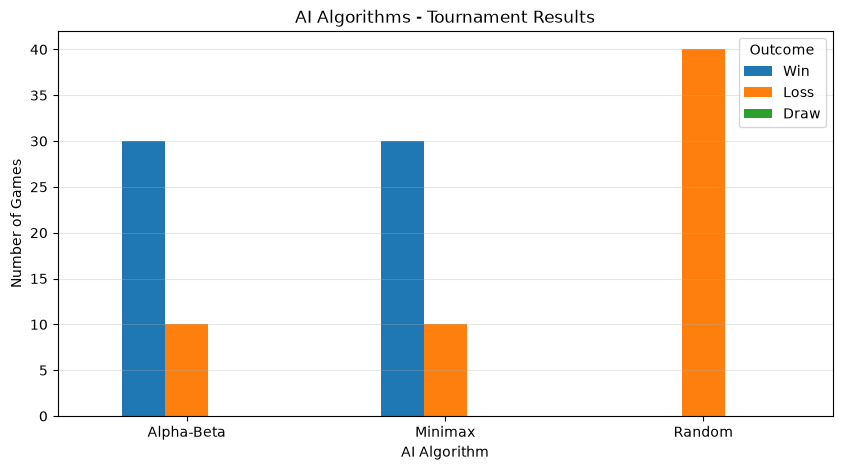

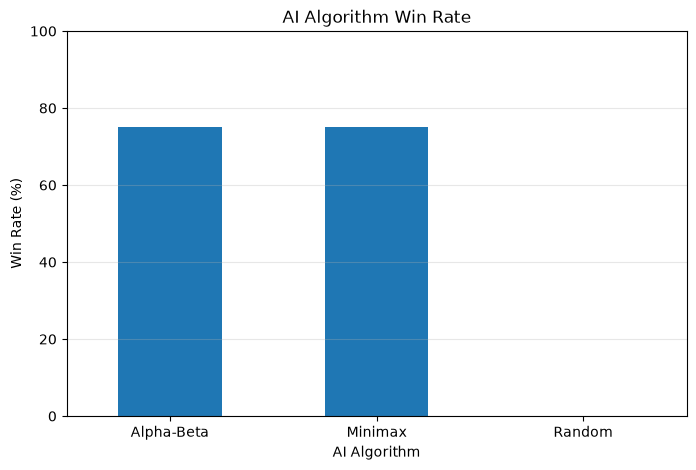

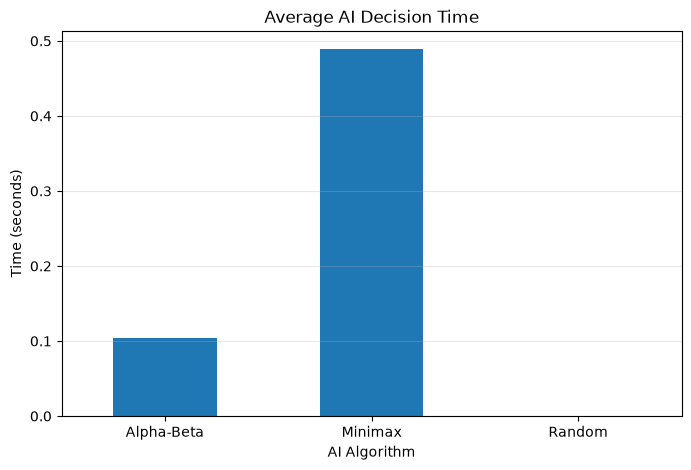

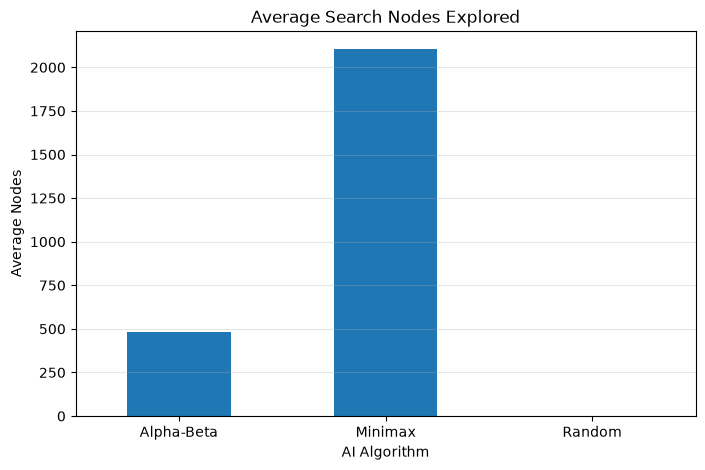


PERFORMANCE SUMMARY

Alpha-Beta
Win Rate: 75.0 %
Average Time: 0.103585 seconds
Average Nodes: 484.29

Minimax
Win Rate: 75.0 %
Average Time: 0.48871 seconds
Average Nodes: 2102.93

Random
Win Rate: 0.0 %
Average Time: 0.000114 seconds
Average Nodes: 0.0


In [23]:

# ============================================
# Cell 13: Tournament Analysis and Graphs
# ============================================

# Calculate overall results
summary = tournament_df.groupby(
    ["Algorithm", "Outcome"]
).size().unstack(fill_value=0)

for outcome in ["Win", "Loss", "Draw"]:
    if outcome not in summary.columns:
        summary[outcome] = 0

summary["Total Games"] = summary[
    ["Win", "Loss", "Draw"]
].sum(axis=1)

summary["Win Rate (%)"] = (
    summary["Win"] / summary["Total Games"] * 100
)

print("AI TOURNAMENT RESULTS")
print("=====================")

display(summary.round(2))


# Graph 1: Wins, Losses and Draws
summary[["Win", "Loss", "Draw"]].plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("AI Algorithms - Tournament Results")
plt.xlabel("AI Algorithm")
plt.ylabel("Number of Games")
plt.xticks(rotation=0)
plt.legend(title="Outcome")
plt.grid(axis="y", alpha=0.3)
plt.show()


# Graph 2: Win Rate
summary["Win Rate (%)"].plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("AI Algorithm Win Rate")
plt.xlabel("AI Algorithm")
plt.ylabel("Win Rate (%)")
plt.xticks(rotation=0)
plt.ylim(0, 100)
plt.grid(axis="y", alpha=0.3)
plt.show()


# Graph 3: Average Execution Time
time_summary = tournament_df.groupby(
    "Algorithm"
)["Average Time"].mean()

time_summary.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Average AI Decision Time")
plt.xlabel("AI Algorithm")
plt.ylabel("Time (seconds)")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.show()


# Graph 4: Average Nodes Explored
node_summary = tournament_df.groupby(
    "Algorithm"
)["Average Nodes"].mean()

node_summary.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Average Search Nodes Explored")
plt.xlabel("AI Algorithm")
plt.ylabel("Average Nodes")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.show()


print("\nPERFORMANCE SUMMARY")
print("===================")

for algorithm in summary.index:
    print(f"\n{algorithm}")
    print("Win Rate:", round(summary.loc[algorithm, "Win Rate (%)"], 2), "%")
    print("Average Time:", round(time_summary[algorithm], 6), "seconds")
    print("Average Nodes:", round(node_summary[algorithm], 2))


In [27]:

# ============================================
# Cell 14: Search Depth Comparison
# ============================================

def generate_test_position(num_moves=10):
    """Generate a random non-terminal board position."""

    board = create_board()
    current_player = AI

    for _ in range(num_moves):
        if is_terminal_node(board):
            break

        col = random_ai_move(board)
        make_move(board, col, current_player)

        if winning_move(board, current_player):
            break

        current_player = (
            PLAYER if current_player == AI else AI
        )

    return board


depth_results = []

# Generate several test positions
test_positions = [
    generate_test_position(10)
    for _ in range(5)
]

depths = [2, 3, 4, 5]

for position_number, board in enumerate(test_positions, 1):

    print(f"\nTest Position {position_number}")

    for depth in depths:

        for algorithm in ["Minimax", "Alpha-Beta"]:

            result = get_experimental_move(
                board, AI, algorithm, depth
            )

            depth_results.append({
                "Position": position_number,
                "Depth": depth,
                "Algorithm": algorithm,
                "Time": result["time"],
                "Nodes": result["nodes"],
                "Score": result["score"]
            })

            print(
                f"{algorithm} | Depth {depth} | "
                f"Nodes: {result['nodes']} | "
                f"Time: {result['time']:.5f}s | "
                f"Score: {result['score']}"
            )


depth_df = pd.DataFrame(depth_results)

print("\nDepth experiment completed!")
display(depth_df.head(10))


Positions tested: 90
Score mismatches: 0

Test Position 1
Minimax | Depth 2 | Nodes: 50 | Time: 0.01087s | Score: 100000
Alpha-Beta | Depth 2 | Nodes: 14 | Time: 0.00296s | Score: 100000
Minimax | Depth 3 | Nodes: 344 | Time: 0.07935s | Score: 100000
Alpha-Beta | Depth 3 | Nodes: 56 | Time: 0.01451s | Score: 100000
Minimax | Depth 4 | Nodes: 2065 | Time: 0.51009s | Score: 100000
Alpha-Beta | Depth 4 | Nodes: 96 | Time: 0.02022s | Score: 100000
Minimax | Depth 5 | Nodes: 13746 | Time: 2.78498s | Score: 100000
Alpha-Beta | Depth 5 | Nodes: 370 | Time: 0.06659s | Score: 100000

Test Position 2
Minimax | Depth 2 | Nodes: 57 | Time: 0.01246s | Score: 10
Alpha-Beta | Depth 2 | Nodes: 35 | Time: 0.00641s | Score: 10
Minimax | Depth 3 | Nodes: 399 | Time: 0.07811s | Score: 31
Alpha-Beta | Depth 3 | Nodes: 170 | Time: 0.03270s | Score: 31
Minimax | Depth 4 | Nodes: 2690 | Time: 0.58944s | Score: 20
Alpha-Beta | Depth 4 | Nodes: 724 | Time: 0.15733s | Score: 20
Minimax | Depth 5 | Nodes: 18132 |

,Position,Depth,Algorithm,Time,Nodes,Score
0,1,2,Minimax,0.010870,50,100000
1,1,2,Alpha-Beta,0.002964,14,100000
2,1,3,Minimax,0.079350,344,100000
3,1,3,Alpha-Beta,0.014514,56,100000
4,1,4,Minimax,0.510092,2065,100000
5,1,4,Alpha-Beta,0.020222,96,100000
6,1,5,Minimax,2.784980,13746,100000
7,1,5,Alpha-Beta,0.066589,370,100000
8,2,2,Minimax,0.012461,57,10
9,2,2,Alpha-Beta,0.006415,35,10


In [28]:
# Verification: Minimax and Alpha-Beta should always agree
mismatches = 0
for _ in range(30):
    board = generate_test_position(10)
    for depth in [2, 3, 4]:
        m = get_experimental_move(board, AI, "Minimax", depth)["score"]
        a = get_experimental_move(board, AI, "Alpha-Beta", depth)["score"]
        if m != a:
            mismatches += 1

print("Positions tested:", 30 * 3)
print("Score mismatches:", mismatches)

Positions tested: 90
Score mismatches: 0


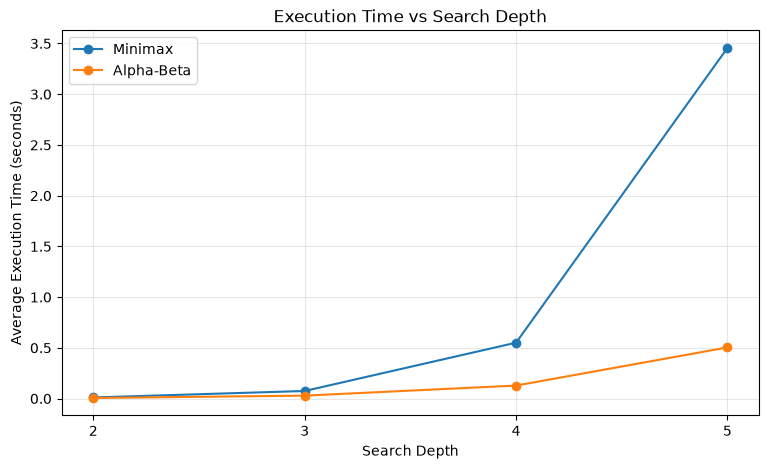

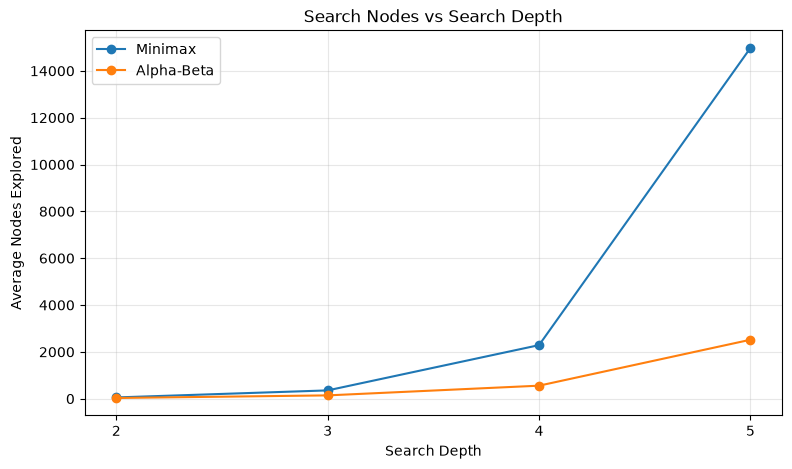

SEARCH DEPTH PERFORMANCE


,Depth,Algorithm,Time,Nodes
0,2,Alpha-Beta,0.00562,29.8
1,2,Minimax,0.01088,53.8
2,3,Alpha-Beta,0.02886,141.4
3,3,Minimax,0.07471,354.2
4,4,Alpha-Beta,0.12800,556.0
5,4,Minimax,0.55070,2287.6
6,5,Alpha-Beta,0.50397,2517.0
7,5,Minimax,3.45563,14975.6


In [25]:

# ============================================
# Cell 15: Search Depth Performance Graphs
# ============================================

depth_summary = depth_df.groupby(
    ["Depth", "Algorithm"]
).agg({
    "Time": "mean",
    "Nodes": "mean"
}).reset_index()

# Execution time comparison
plt.figure(figsize=(9, 5))

for algorithm in ["Minimax", "Alpha-Beta"]:
    data = depth_summary[
        depth_summary["Algorithm"] == algorithm
    ]

    plt.plot(
        data["Depth"],
        data["Time"],
        marker="o",
        label=algorithm
    )

plt.title("Execution Time vs Search Depth")
plt.xlabel("Search Depth")
plt.ylabel("Average Execution Time (seconds)")
plt.xticks(depths)
plt.legend()
plt.grid(alpha=0.3)
plt.show()


# Nodes explored comparison
plt.figure(figsize=(9, 5))

for algorithm in ["Minimax", "Alpha-Beta"]:
    data = depth_summary[
        depth_summary["Algorithm"] == algorithm
    ]

    plt.plot(
        data["Depth"],
        data["Nodes"],
        marker="o",
        label=algorithm
    )

plt.title("Search Nodes vs Search Depth")
plt.xlabel("Search Depth")
plt.ylabel("Average Nodes Explored")
plt.xticks(depths)
plt.legend()
plt.grid(alpha=0.3)
plt.show()


# Display comparison table
print("SEARCH DEPTH PERFORMANCE")
display(depth_summary.round(5))


                                   Nodes    Time
Depth Version                                   
3     Ordering + Trans. Table    138.500  0.0327
      Plain Alpha-Beta           197.250  0.0426
      With Move Ordering         138.500  0.0303
4     Ordering + Trans. Table    388.375  0.0718
      Plain Alpha-Beta           638.625  0.1286
      With Move Ordering         392.375  0.0786
5     Ordering + Trans. Table   2178.875  0.4517
      Plain Alpha-Beta          3456.750  0.7367
      With Move Ordering        2212.125  0.4661
6     Ordering + Trans. Table   5286.125  1.0424
      Plain Alpha-Beta         10608.500  2.2371
      With Move Ordering        5648.125  1.1614


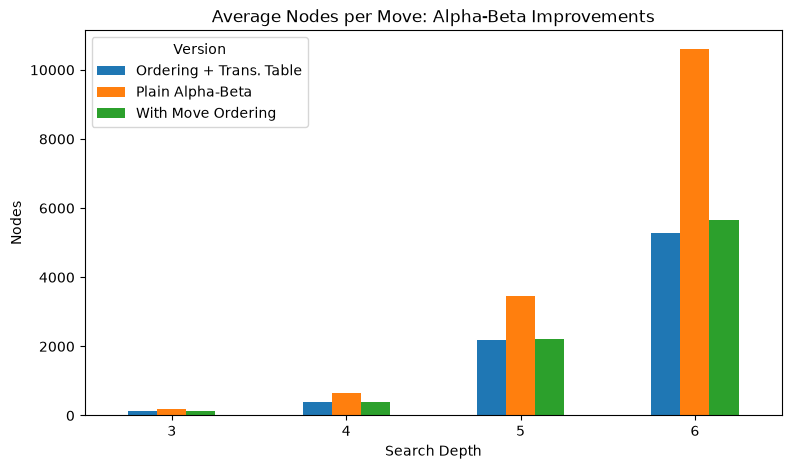

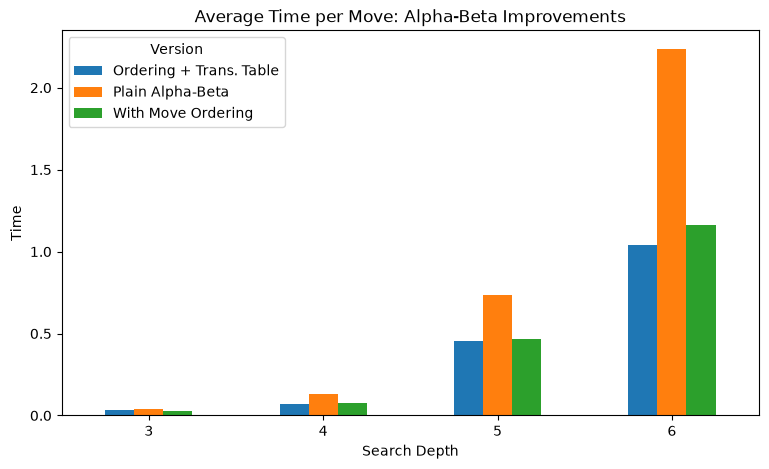

In [26]:
# ============================================
# Cell 16b: Improved Alpha-Beta (Move Ordering + Transposition Table)
# ============================================

nodes_count = 0
tt = {}   # transposition table: remembers scores of positions already searched


def alpha_beta_v2(board, depth, alpha, beta, maximizing, use_order, use_tt):
    global nodes_count
    nodes_count += 1

    # Have we already searched this exact position at this depth?
    key = (board.tobytes(), depth, maximizing)
    if use_tt and key in tt:
        return None, tt[key]

    terminal = is_terminal_node(board)

    if depth == 0 or terminal:
        if terminal:
            if winning_move(board, AI):
                return None, WIN_SCORE
            elif winning_move(board, PLAYER):
                return None, -WIN_SCORE
            else:
                return None, 0
        return None, score_position(board, AI)

    moves = get_valid_locations(board)

    # Move ordering: try centre columns first (3, 2, 4, 1, 5, 0, 6)
    if use_order:
        moves = sorted(moves, key=lambda c: abs(c - COLS // 2))

    alpha_start = alpha
    beta_start = beta
    best_col = moves[0]

    if maximizing:
        value = -math.inf
        for col in moves:
            row = get_next_open_row(board, col)
            temp_board = board.copy()
            drop_piece(temp_board, row, col, AI)

            new_score = alpha_beta_v2(temp_board, depth - 1, alpha, beta,
                                      False, use_order, use_tt)[1]
            if new_score > value:
                value = new_score
                best_col = col

            alpha = max(alpha, value)
            if alpha >= beta:
                break
    else:
        value = math.inf
        for col in moves:
            row = get_next_open_row(board, col)
            temp_board = board.copy()
            drop_piece(temp_board, row, col, PLAYER)

            new_score = alpha_beta_v2(temp_board, depth - 1, alpha, beta,
                                      True, use_order, use_tt)[1]
            if new_score < value:
                value = new_score
                best_col = col

            beta = min(beta, value)
            if alpha >= beta:
                break

    # Only save exact scores (not ones where pruning cut the search short)
    if use_tt and alpha_start < value < beta_start:
        tt[key] = value

    return best_col, value


def run_version(board, depth, use_order, use_tt):
    global nodes_count, tt
    nodes_count = 0
    tt = {}
    start = time.time()
    col, score = alpha_beta_v2(board, depth, -math.inf, math.inf,
                               True, use_order, use_tt)
    return score, nodes_count, time.time() - start


# ---------- Experiment ----------
versions = {
    "Plain Alpha-Beta":       (False, False),
    "With Move Ordering":     (True,  False),
    "Ordering + Trans. Table": (True,  True),
}

results = []

for p in range(8):                      # 8 random positions
    board = generate_test_position(10)
    for depth in [3, 4, 5, 6]:
        scores = []
        for name, (order, table) in versions.items():
            score, nodes, t = run_version(board, depth, order, table)
            scores.append(score)
            results.append({"Position": p, "Depth": depth, "Version": name,
                            "Nodes": nodes, "Time": t})
        # Sanity check: all versions must give the same score
        if len(set(scores)) != 1:
            print("WARNING: scores differ at position", p, "depth", depth, scores)

improve_df = pd.DataFrame(results)
summary = improve_df.groupby(["Depth", "Version"])[["Nodes", "Time"]].mean()
print(summary.round(4))

# Graphs
for metric in ["Nodes", "Time"]:
    improve_df.groupby(["Depth", "Version"])[metric].mean().unstack().plot(
        kind="bar", figsize=(9, 5))
    plt.title(f"Average {metric} per Move: Alpha-Beta Improvements")
    plt.xlabel("Search Depth")
    plt.ylabel(metric)
    plt.xticks(rotation=0)
    plt.show()

In [31]:
# ============================================
# Cell 16c: Weighted Evaluation and Games for the GA
# ============================================

HAND_WEIGHTS = [6, 5, 10, 12]   # [center, two-in-row, three-in-row, block-opponent-three]

# All 69 groups of 4 cells on the board (built once, so evaluation is fast)
WINDOWS = []
for r in range(ROWS):
    for c in range(COLS - 3):
        WINDOWS.append([(r, c + i) for i in range(4)])          # horizontal
for r in range(ROWS - 3):
    for c in range(COLS):
        WINDOWS.append([(r + i, c) for i in range(4)])          # vertical
for r in range(ROWS - 3):
    for c in range(COLS - 3):
        WINDOWS.append([(r + i, c + i) for i in range(4)])      # diagonal
for r in range(3, ROWS):
    for c in range(COLS - 3):
        WINDOWS.append([(r - i, c + i) for i in range(4)])      # other diagonal


def score_position_w(board, piece, w):
    center_w, two_w, three_w, block_w = w
    opp = PLAYER if piece == AI else AI

    score = list(board[:, COLS // 2]).count(piece) * center_w

    for cells in WINDOWS:
        window = [board[r][c] for r, c in cells]
        mine = window.count(piece)
        theirs = window.count(opp)
        empty = window.count(EMPTY)

        # Keep the original evaluation's winning-window score
        if mine == 4:
            score += 100
        elif mine == 3 and empty == 1:
            score += three_w
        elif mine == 2 and empty == 2:
            score += two_w

        if theirs == 3 and empty == 1:
            score -= block_w

    return score



def ab_weighted(board, depth, alpha, beta, maximizing, w):
    """Alpha-beta with move ordering, using weights w in the evaluation."""
    terminal = is_terminal_node(board)

    if depth == 0 or terminal:
        if terminal:
            if winning_move(board, AI):
                return None, WIN_SCORE
            elif winning_move(board, PLAYER):
                return None, -WIN_SCORE
            return None, 0
        return None, score_position_w(board, AI, w)

    moves = sorted(get_valid_locations(board), key=lambda c: abs(c - COLS // 2))
    best_col = moves[0]

    if maximizing:
        value = -math.inf
        for col in moves:
            temp = board.copy()
            drop_piece(temp, get_next_open_row(temp, col), col, AI)
            score = ab_weighted(temp, depth - 1, alpha, beta, False, w)[1]
            if score > value:
                value, best_col = score, col
            alpha = max(alpha, value)
            if alpha >= beta:
                break
    else:
        value = math.inf
        for col in moves:
            temp = board.copy()
            drop_piece(temp, get_next_open_row(temp, col), col, PLAYER)
            score = ab_weighted(temp, depth - 1, alpha, beta, True, w)[1]
            if score < value:
                value, best_col = score, col
            beta = min(beta, value)
            if alpha >= beta:
                break

    return best_col, value


def weighted_move(board, piece, w, depth):
    # Make the current mover look like AI, then search
    b = board.copy() if piece == AI else swap_perspective(board)
    return ab_weighted(b, depth, -math.inf, math.inf, True, w)[0]


def play_weighted_game(w_a, w_b, depth=2,
                       a_first=True, seed=None):

    board = create_board()
    rng = random.Random(seed)

    turn = AI if a_first else PLAYER

    # Reproducible random opening
    for _ in range(4):
        valid = get_valid_locations(board)

        if not valid:
            break

        col = rng.choice(valid)
        make_move(board, col, turn)

        turn = PLAYER if turn == AI else AI

    while not is_terminal_node(board):

        w = w_a if turn == AI else w_b

        col = weighted_move(board, turn, w, depth)

        if col is None:
            break

        make_move(board, col, turn)

        if winning_move(board, turn):
            return "A" if turn == AI else "B"

        turn = PLAYER if turn == AI else AI

    return "Draw"


def fitness(w, baseline, games=10, depth=2):

    points = 0

    for g in range(games):

        # Every chromosome receives identical opening positions
        result = play_weighted_game(
            w,
            baseline,
            depth,
            a_first=(g % 2 == 0),
            seed=10000 + g
        )

        if result == "A":
            points += 1
        elif result == "Draw":
            points += 0.5

    return points / games


# Check: with the hand weights, the new evaluation matches the original one
for _ in range(20):
    b = generate_test_position(10)
    assert score_position_w(b, AI, HAND_WEIGHTS) == score_position(b, AI)
print("Weighted evaluation matches the original evaluation.")

Weighted evaluation matches the original evaluation.


Generation 1/15 | Generation best: 0.65 | Best so far: 0.65 | Average: 0.48 | Weights: [22, 22, 38, 16]
Generation 2/15 | Generation best: 0.65 | Best so far: 0.65 | Average: 0.49 | Weights: [22, 22, 38, 16]
Generation 3/15 | Generation best: 0.65 | Best so far: 0.65 | Average: 0.49 | Weights: [22, 22, 38, 16]
Generation 4/15 | Generation best: 0.75 | Best so far: 0.75 | Average: 0.50 | Weights: [22, 13, 39, 16]
Generation 5/15 | Generation best: 0.80 | Best so far: 0.80 | Average: 0.61 | Weights: [15, 13, 39, 16]
Generation 6/15 | Generation best: 0.80 | Best so far: 0.80 | Average: 0.67 | Weights: [15, 13, 39, 16]
Generation 7/15 | Generation best: 0.80 | Best so far: 0.80 | Average: 0.70 | Weights: [15, 13, 39, 16]
Generation 8/15 | Generation best: 0.80 | Best so far: 0.80 | Average: 0.68 | Weights: [15, 13, 39, 16]
Generation 9/15 | Generation best: 0.80 | Best so far: 0.80 | Average: 0.67 | Weights: [15, 13, 39, 16]
Generation 10/15 | Generation best: 0.80 | Best so far: 0.80 | A

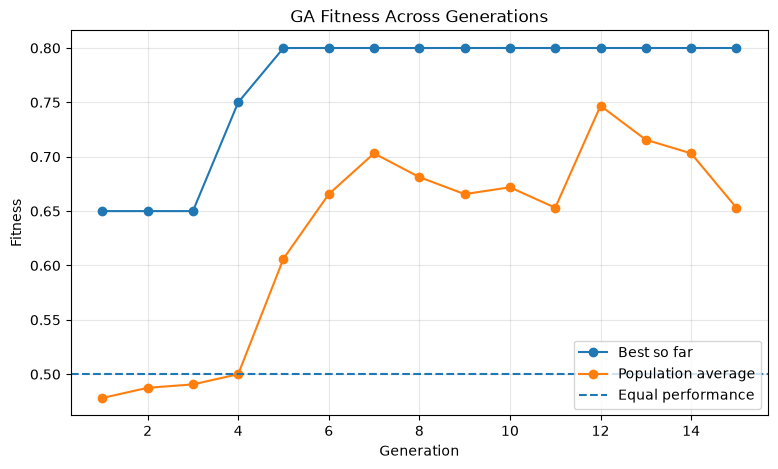

In [32]:

# ============================================
# GA with Reproducible Fitness Evaluation
# ============================================

random.seed(42)

POP_SIZE = 16
GENERATIONS = 15
GAMES_PER_FITNESS = 10
TRAIN_DEPTH = 2
MUTATION_RATE = 0.25
GENE_MIN, GENE_MAX = 0, 40


def random_chromosome():
    return [
        random.randint(GENE_MIN, GENE_MAX)
        for _ in range(4)
    ]


def select_parent(population, fits):
    picks = random.sample(range(len(population)), 3)
    best = max(picks, key=lambda i: fits[i])
    return population[best]


def crossover(p1, p2):
    point = random.randint(1, 3)
    return p1[:point] + p2[point:]


def mutate(chromosome):
    for i in range(len(chromosome)):
        if random.random() < MUTATION_RATE:
            chromosome[i] += random.randint(-5, 5)
            chromosome[i] = max(
                GENE_MIN,
                min(GENE_MAX, chromosome[i])
            )
    return chromosome


population = [
    random_chromosome() for _ in range(POP_SIZE)
]

best_history = []
avg_history = []
generation_best_history = []

best_weights = None
best_fit = -1

ga_start = time.time()

for gen in range(GENERATIONS):

    fits = [
        fitness(ch, HAND_WEIGHTS,
                GAMES_PER_FITNESS, TRAIN_DEPTH)
        for ch in population
    ]

    order = sorted(
        range(POP_SIZE),
        key=lambda i: fits[i],
        reverse=True
    )

    generation_best = fits[order[0]]

    if generation_best > best_fit:
        best_fit = generation_best
        best_weights = population[order[0]][:]

    # Best-so-far is cumulative and cannot decrease
    best_history.append(best_fit)
    generation_best_history.append(generation_best)
    avg_history.append(sum(fits) / POP_SIZE)

    print(
        f"Generation {gen + 1}/{GENERATIONS} | "
        f"Generation best: {generation_best:.2f} | "
        f"Best so far: {best_fit:.2f} | "
        f"Average: {avg_history[-1]:.2f} | "
        f"Weights: {population[order[0]]}"
    )

    # Elitism: preserve the two best chromosomes
    new_pop = [
        population[order[0]][:],
        population[order[1]][:]
    ]

    while len(new_pop) < POP_SIZE:
        p1 = select_parent(population, fits)
        p2 = select_parent(population, fits)

        child = crossover(p1, p2)
        new_pop.append(mutate(child))

    population = new_pop


print("\nGA finished in",
      round(time.time() - ga_start), "seconds")

print("Best weights:", best_weights)
print("Best fitness:", best_fit)
print("Hand-tuned weights:", HAND_WEIGHTS)


plt.figure(figsize=(9, 5))

plt.plot(
    range(1, GENERATIONS + 1),
    best_history,
    marker="o",
    label="Best so far"
)

plt.plot(
    range(1, GENERATIONS + 1),
    avg_history,
    marker="o",
    label="Population average"
)

plt.axhline(
    0.5,
    linestyle="--",
    label="Equal performance"
)

plt.title("GA Fitness Across Generations")
plt.xlabel("Generation")
plt.ylabel("Fitness")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


Depth 2 completed
Depth 3 completed
Depth 4 completed


,Depth,GA Wins,Hand Wins,Draws,GA Score (%)
0,2,10,10,0,50.0
1,3,7,12,1,37.5
2,4,10,9,1,52.5


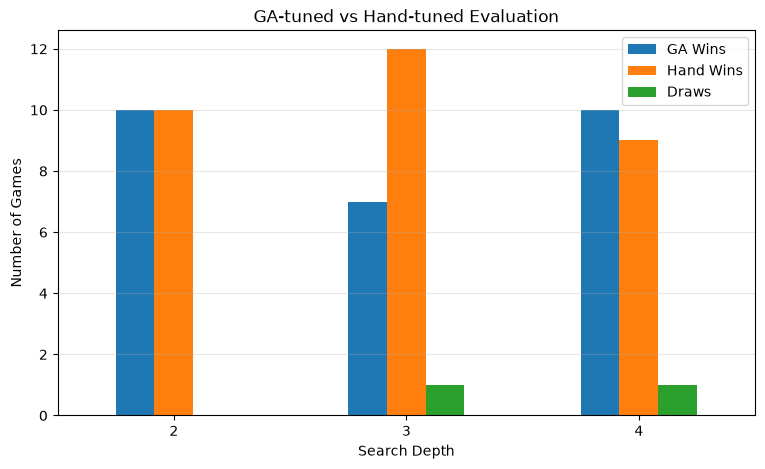

In [33]:
# ============================================
# Cell 16e: Final Test - GA Weights vs Hand-Tuned Weights
# ============================================


# ============================================
# Independent Test: GA vs Hand-Tuned Weights
# ============================================

TEST_GAMES = 20
final_results = []

for depth in [2, 3, 4]:

    wins = 0
    losses = 0
    draws = 0

    for g in range(TEST_GAMES):

        result = play_weighted_game(
            best_weights,
            HAND_WEIGHTS,
            depth=depth,
            a_first=(g % 2 == 0),
            seed=90000 + g
        )

        if result == "A":
            wins += 1
        elif result == "B":
            losses += 1
        else:
            draws += 1

    ga_score = (
        wins + 0.5 * draws
    ) / TEST_GAMES * 100

    final_results.append({
        "Depth": depth,
        "GA Wins": wins,
        "Hand Wins": losses,
        "Draws": draws,
        "GA Score (%)": round(ga_score, 2)
    })

    print(f"Depth {depth} completed")


final_df = pd.DataFrame(final_results)

display(final_df)

final_df.set_index("Depth")[
    ["GA Wins", "Hand Wins", "Draws"]
].plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("GA-tuned vs Hand-tuned Evaluation")
plt.xlabel("Search Depth")
plt.ylabel("Number of Games")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.show()


In [ ]:

# ============================================
# Cell 16: Reinforcement Learning Setup
# Deep Q-Network (DQN)
# ============================================

import torch
import torch.nn as nn
import torch.optim as optim

from collections import deque
import copy

# Reproducibility
torch.manual_seed(42)
np.random.seed(42)
random.seed(42)

# Select GPU if available
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("RL Device:", device)


# DQN Neural Network
class DQN(nn.Module):

    def __init__(self):
        super(DQN, self).__init__()

        self.network = nn.Sequential(
            nn.Linear(ROWS * COLS, 128),
            nn.ReLU(),

            nn.Linear(128, 128),
            nn.ReLU(),

            nn.Linear(128, COLS)
        )

    def forward(self, state):
        return self.network(state)


# Create online and target networks
rl_model = DQN().to(device)

target_model = copy.deepcopy(rl_model).to(device)
target_model.eval()

optimizer = optim.Adam(
    rl_model.parameters(),
    lr=0.001
)

loss_function = nn.SmoothL1Loss()


# Experience Replay Memory
replay_memory = deque(maxlen=50000)

# RL Hyperparameters
RL_GAMMA = 0.99
RL_EPSILON = 1.0
RL_EPSILON_MIN = 0.05
RL_EPSILON_DECAY = 0.9995

RL_BATCH_SIZE = 64
RL_LEARNING_RATE = 0.001
RL_TARGET_UPDATE = 500

print("DQN model created successfully!")
print("Input neurons:", ROWS * COLS)
print("Output neurons:", COLS)
print("Replay memory capacity:", replay_memory.maxlen)


RL Device: cuda
DQN model created successfully!
Input neurons: 42
Output neurons: 7
Replay memory capacity: 50000


In [ ]:

# ============================================
# Cell 17: RL State Representation and Agent
# ============================================

def encode_state(board, current_player):
    """Encode board from current player's perspective."""

    state = np.zeros((ROWS, COLS), dtype=np.float32)

    state[board == current_player] = 1.0

    opponent = PLAYER if current_player == AI else AI
    state[board == opponent] = -1.0

    return state.flatten()


def get_rl_action(board, current_player, epsilon=0.0):
    """Choose a valid action using epsilon-greedy policy."""

    valid_moves = get_valid_locations(board)

    if not valid_moves:
        return None

    # Exploration
    if random.random() < epsilon:
        return random.choice(valid_moves)

    state = encode_state(board, current_player)

    state_tensor = torch.FloatTensor(state).unsqueeze(0).to(device)

    with torch.no_grad():
        q_values = rl_model(state_tensor).squeeze(0)

    # Ignore invalid columns
    masked_q_values = q_values.clone()

    for col in range(COLS):
        if col not in valid_moves:
            masked_q_values[col] = -float("inf")

    return int(torch.argmax(masked_q_values).item())


def store_experience(state, action, reward, next_state, done):
    replay_memory.append((
        state,
        action,
        reward,
        next_state,
        done
    ))


print("RL state representation ready!")

test_board = create_board()
make_move(test_board, 3, PLAYER)

print("Encoded board shape:",
      encode_state(test_board, AI).shape)
print("Valid RL action:",
      get_rl_action(test_board, AI))


RL state representation ready!
Encoded board shape: (42,)
Valid RL action: 4


In [ ]:

# ============================================
# Cell 18: DQN Training Function
# ============================================

training_steps = 0


def train_dqn():

    global training_steps

    if len(replay_memory) < RL_BATCH_SIZE:
        return None

    batch = random.sample(
        replay_memory,
        RL_BATCH_SIZE
    )

    states, actions, rewards, next_states, dones = zip(*batch)

    states = torch.FloatTensor(
        np.array(states)
    ).to(device)

    actions = torch.LongTensor(
        actions
    ).unsqueeze(1).to(device)

    rewards = torch.FloatTensor(
        rewards
    ).to(device)

    next_states = torch.FloatTensor(
        np.array(next_states)
    ).to(device)

    dones = torch.FloatTensor(
        dones
    ).to(device)

    # Current Q-values
    current_q = rl_model(states).gather(
        1, actions
    ).squeeze(1)

    # Target Q-values
    with torch.no_grad():

        next_q = target_model(next_states)

        # Negation because next state is from opponent's perspective
        max_next_q = next_q.max(dim=1)[0]

        target_q = rewards - (
            RL_GAMMA * max_next_q * (1 - dones)
        )

    loss = loss_function(current_q, target_q)

    optimizer.zero_grad()
    loss.backward()

    torch.nn.utils.clip_grad_norm_(
        rl_model.parameters(), 1.0
    )

    optimizer.step()

    training_steps += 1

    # Periodically update target network
    if training_steps % RL_TARGET_UPDATE == 0:
        target_model.load_state_dict(
            rl_model.state_dict()
        )

    return loss.item()


print("DQN training function ready!")


DQN training function ready!


In [ ]:

# ============================================
# RL Hyperparameter Initialization - FIX
# ============================================

RL_GAMMA = 0.99

RL_EPSILON = 1.0
RL_EPSILON_MIN = 0.05
RL_EPSILON_DECAY = 0.9995

RL_BATCH_SIZE = 64
RL_LEARNING_RATE = 0.001
RL_TARGET_UPDATE = 500

training_steps = 0

from collections import deque

replay_memory = deque(maxlen=50000)

training_steps = 0

print("Replay memory initialized successfully!")
print("Capacity:", replay_memory.maxlen)
print("Current size:", len(replay_memory))

print("RL hyperparameters initialized successfully!")
print("Initial Epsilon:", RL_EPSILON)
print("Minimum Epsilon:", RL_EPSILON_MIN)
print("Batch Size:", RL_BATCH_SIZE)


Replay memory initialized successfully!
Capacity: 50000
Current size: 0
RL hyperparameters initialized successfully!
Initial Epsilon: 1.0
Minimum Epsilon: 0.05
Batch Size: 64


In [ ]:

# ============================================
# Cell 19: DQN Self-Play Training
# ============================================

def play_rl_self_game(epsilon):
    """
    Play one complete game using the same RL agent
    for both players.
    """

    board = create_board()
    current_player = AI
    total_moves = 0

    while not is_terminal_node(board):

        # Encode current board from current player's perspective
        state = encode_state(board, current_player)

        # Select action using epsilon-greedy policy
        action = get_rl_action(
            board,
            current_player,
            epsilon
        )

        if action is None:
            return total_moves, "Draw"

        # Execute selected move
        make_move(board, action, current_player)
        total_moves += 1

        # Check whether current player won
        if winning_move(board, current_player):

            next_state = np.zeros(
                ROWS * COLS,
                dtype=np.float32
            )

            store_experience(
                state,
                action,
                1.0,
                next_state,
                True
            )

            return total_moves, current_player

        # Check draw
        if is_draw(board):

            next_state = np.zeros(
                ROWS * COLS,
                dtype=np.float32
            )

            store_experience(
                state,
                action,
                0.0,
                next_state,
                True
            )

            return total_moves, "Draw"

        # Switch to opponent
        next_player = (
            PLAYER if current_player == AI else AI
        )

        # Encode next state from opponent's perspective
        next_state = encode_state(
            board,
            next_player
        )

        # Store experience
        store_experience(
            state,
            action,
            0.0,
            next_state,
            False
        )

        current_player = next_player

    return total_moves, "Draw"


# ============================================
# DQN Training Loop
# ============================================

def train_rl_agent(episodes=5000):

    global RL_EPSILON

    history = []

    first_player_wins = 0
    second_player_wins = 0
    draws = 0

    print("=" * 55)
    print("       DQN REINFORCEMENT LEARNING")
    print("             SELF-PLAY TRAINING")
    print("=" * 55)

    print("Total Episodes:", episodes)
    print("Initial Epsilon:", RL_EPSILON)
    print("Minimum Epsilon:", RL_EPSILON_MIN)
    print("Batch Size:", RL_BATCH_SIZE)
    print("Replay Memory:", replay_memory.maxlen)
    print("-" * 55)

    for episode in range(1, episodes + 1):

        # Play one self-play game
        total_moves, winner = play_rl_self_game(
            RL_EPSILON
        )

        # Update win/draw statistics
        if winner == AI:
            first_player_wins += 1
            outcome = "First Player Win"

        elif winner == PLAYER:
            second_player_wins += 1
            outcome = "Second Player Win"

        else:
            draws += 1
            outcome = "Draw"

        # Train neural network using replay memory
        episode_losses = []

        for _ in range(2):

            loss = train_dqn()

            if loss is not None:
                episode_losses.append(loss)

        average_loss = (
            np.mean(episode_losses)
            if episode_losses else 0.0
        )

        # Gradually reduce exploration
        RL_EPSILON = max(
            RL_EPSILON_MIN,
            RL_EPSILON * RL_EPSILON_DECAY
        )

        # Store training information
        history.append({
            "Episode": episode,
            "Outcome": outcome,
            "Moves": total_moves,
            "Epsilon": RL_EPSILON,
            "Loss": average_loss,
            "Replay Memory Size": len(replay_memory)
        })

        # Display progress every 100 episodes
        if episode % 100 == 0:

            total = episode

            first_rate = (
                first_player_wins / total
            ) * 100

            second_rate = (
                second_player_wins / total
            ) * 100

            draw_rate = (
                draws / total
            ) * 100

            print(
                f"Episode {episode}/{episodes} | "
                f"Epsilon: {RL_EPSILON:.3f} | "
                f"Loss: {average_loss:.5f} | "
                f"First Wins: {first_rate:.1f}% | "
                f"Second Wins: {second_rate:.1f}% | "
                f"Draws: {draw_rate:.1f}%"
            )

    # Convert history into DataFrame
    history_df = pd.DataFrame(history)

    print("\n" + "=" * 55)
    print("          TRAINING COMPLETED")
    print("=" * 55)

    print("Total Episodes:", episodes)
    print("First Player Wins:", first_player_wins)
    print("Second Player Wins:", second_player_wins)
    print("Draws:", draws)
    print("Final Epsilon:", round(RL_EPSILON, 4))
    print("Training Steps:", training_steps)
    print("Replay Memory Size:", len(replay_memory))

    return history_df


# ============================================
# Start Self-Play Training
# ============================================

rl_history = train_rl_agent(
    episodes=5000
)

print("\nTraining history:")
display(rl_history.head())

print("\nLast training episodes:")
display(rl_history.tail())


       DQN REINFORCEMENT LEARNING
             SELF-PLAY TRAINING
Total Episodes: 5000
Initial Epsilon: 1.0
Minimum Epsilon: 0.05
Batch Size: 64
Replay Memory: 50000
-------------------------------------------------------
Episode 100/5000 | Epsilon: 0.951 | Loss: 0.01120 | First Wins: 63.0% | Second Wins: 37.0% | Draws: 0.0%
Episode 200/5000 | Epsilon: 0.905 | Loss: 0.01421 | First Wins: 63.0% | Second Wins: 36.5% | Draws: 0.5%
Episode 300/5000 | Epsilon: 0.861 | Loss: 0.02434 | First Wins: 62.0% | Second Wins: 37.7% | Draws: 0.3%
Episode 400/5000 | Epsilon: 0.819 | Loss: 0.02266 | First Wins: 61.8% | Second Wins: 38.0% | Draws: 0.2%
Episode 500/5000 | Epsilon: 0.779 | Loss: 0.01642 | First Wins: 61.0% | Second Wins: 38.8% | Draws: 0.2%
Episode 600/5000 | Epsilon: 0.741 | Loss: 0.02620 | First Wins: 59.5% | Second Wins: 40.3% | Draws: 0.2%
Episode 700/5000 | Epsilon: 0.705 | Loss: 0.01354 | First Wins: 59.9% | Second Wins: 39.9% | Draws: 0.3%
Episode 800/5000 | Epsilon: 0.670 | Loss: 0

,Episode,Outcome,Moves,Epsilon,Loss,Replay Memory Size
0,1,Second Player Win,24,0.999500,0.000000,24
1,2,Second Player Win,26,0.999000,0.000000,50
2,3,First Player Win,11,0.998501,0.000000,61
3,4,First Player Win,31,0.998001,0.022568,92
4,5,First Player Win,9,0.997502,0.012493,101



Last training episodes:


,Episode,Outcome,Moves,Epsilon,Loss,Replay Memory Size
4995,4996,Second Player Win,22,0.082198,0.022972,50000
4996,4997,Second Player Win,24,0.082157,0.029073,50000
4997,4998,First Player Win,11,0.082116,0.027732,50000
4998,4999,First Player Win,15,0.082075,0.015812,50000
4999,5000,First Player Win,15,0.082034,0.015649,50000


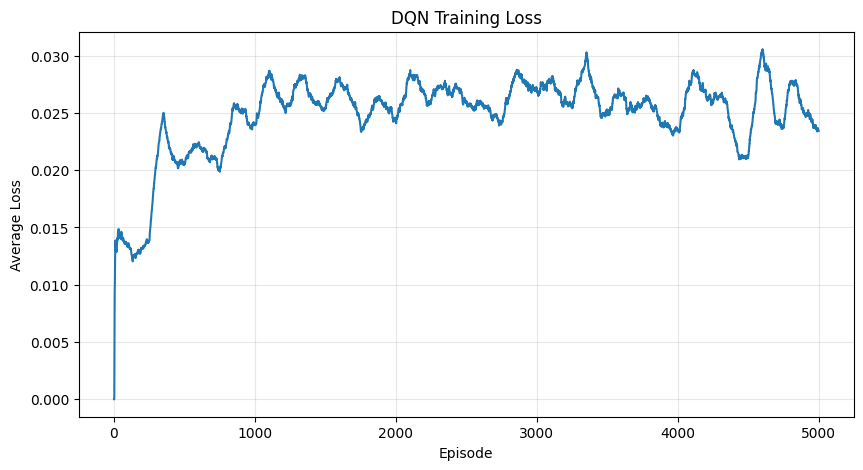

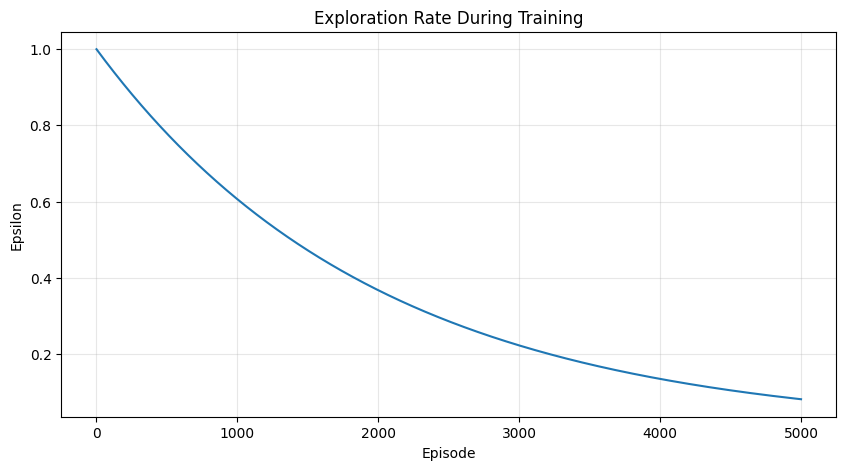

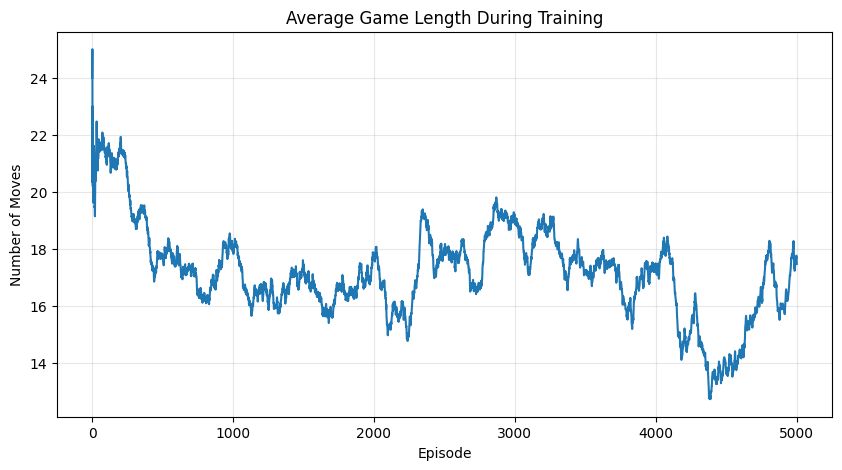

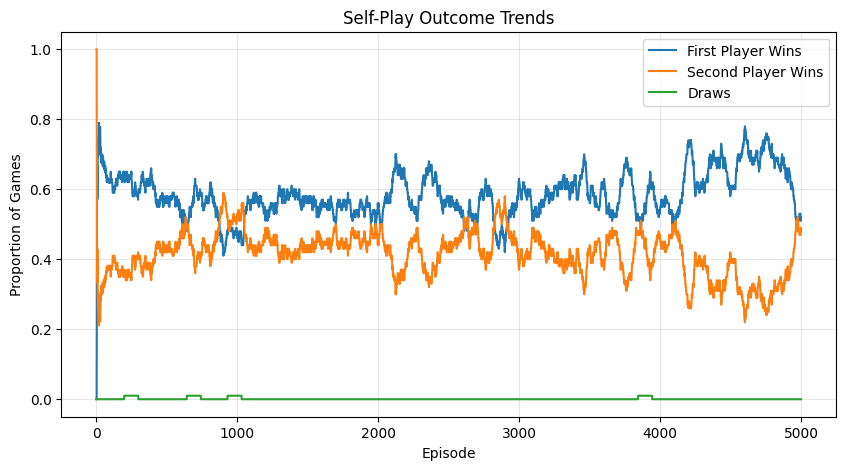

In [ ]:

# ============================================
# Cell 20: RL Learning Progress
# ============================================

# Rolling average helper
def rolling_average(values, window=100):
    return pd.Series(values).rolling(
        window, min_periods=1
    ).mean()


# Plot 1: Training loss
plt.figure(figsize=(10, 5))

plt.plot(
    rl_history["Episode"],
    rolling_average(rl_history["Loss"], 100)
)

plt.title("DQN Training Loss")
plt.xlabel("Episode")
plt.ylabel("Average Loss")
plt.grid(alpha=0.3)
plt.show()


# Plot 2: Exploration rate
plt.figure(figsize=(10, 5))

plt.plot(
    rl_history["Episode"],
    rl_history["Epsilon"]
)

plt.title("Exploration Rate During Training")
plt.xlabel("Episode")
plt.ylabel("Epsilon")
plt.grid(alpha=0.3)
plt.show()


# Plot 3: Average game length
plt.figure(figsize=(10, 5))

plt.plot(
    rl_history["Episode"],
    rolling_average(rl_history["Moves"], 100)
)

plt.title("Average Game Length During Training")
plt.xlabel("Episode")
plt.ylabel("Number of Moves")
plt.grid(alpha=0.3)
plt.show()


# Plot 4: First player vs second player outcomes
outcome_history = rl_history.copy()

outcome_history["First Win"] = (
    outcome_history["Outcome"] == "First Player Win"
).astype(int)

outcome_history["Second Win"] = (
    outcome_history["Outcome"] == "Second Player Win"
).astype(int)

outcome_history["Draw"] = (
    outcome_history["Outcome"] == "Draw"
).astype(int)

plt.figure(figsize=(10, 5))

plt.plot(
    outcome_history["Episode"],
    rolling_average(outcome_history["First Win"], 100),
    label="First Player Wins"
)

plt.plot(
    outcome_history["Episode"],
    rolling_average(outcome_history["Second Win"], 100),
    label="Second Player Wins"
)

plt.plot(
    outcome_history["Episode"],
    rolling_average(outcome_history["Draw"], 100),
    label="Draws"
)

plt.title("Self-Play Outcome Trends")
plt.xlabel("Episode")
plt.ylabel("Proportion of Games")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


In [ ]:

# ============================================
# Cell 21: RL Agent vs Other AI Algorithms
# ============================================

def play_rl_vs_opponent(
    opponent="Minimax",
    opponent_depth=4,
    rl_first=True
):

    board = create_board()

    current_player = AI if rl_first else PLAYER

    while not is_terminal_node(board):

        if current_player == AI:

            # RL agent plays as AI
            col = get_rl_action(
                board, AI, epsilon=0.0
            )

        else:

            # Existing AI plays as PLAYER
            result = get_experimental_move(
                board,
                PLAYER,
                opponent,
                opponent_depth
            )

            col = result["column"]

        if col is None:
            break

        make_move(board, col, current_player)

        if winning_move(board, current_player):

            if current_player == AI:
                return "RL"

            return opponent

        if is_draw(board):
            return "Draw"

        current_player = (
            PLAYER if current_player == AI else AI
        )

    return "Draw"


def evaluate_rl_agent(games=20, depth=4):

    opponents = ["Random", "Minimax", "Alpha-Beta"]

    results = []

    for opponent in opponents:

        wins = 0
        losses = 0
        draws = 0

        print(f"\nRL vs {opponent}")

        for game in range(games):

            # Alternate starting player
            rl_first = game % 2 == 0

            winner = play_rl_vs_opponent(
                opponent=opponent,
                opponent_depth=depth,
                rl_first=rl_first
            )

            if winner == "RL":
                wins += 1

            elif winner == "Draw":
                draws += 1

            else:
                losses += 1

            print(
                f"Game {game + 1}/{games}: {winner}"
            )

        results.append({
            "Opponent": opponent,
            "Wins": wins,
            "Losses": losses,
            "Draws": draws,
            "Win Rate (%)": wins / games * 100,
            "Draw Rate (%)": draws / games * 100
        })

    return pd.DataFrame(results)


# Evaluate trained RL agent
rl_evaluation = evaluate_rl_agent(
    games=20,
    depth=4
)

print("\nRL AGENT EVALUATION")
display(rl_evaluation)



RL vs Random
Game 1/20: RL
Game 2/20: RL
Game 3/20: Random
Game 4/20: RL
Game 5/20: RL
Game 6/20: RL
Game 7/20: RL
Game 8/20: RL
Game 9/20: RL
Game 10/20: RL
Game 11/20: RL
Game 12/20: RL
Game 13/20: RL
Game 14/20: RL
Game 15/20: RL
Game 16/20: RL
Game 17/20: RL
Game 18/20: RL
Game 19/20: RL
Game 20/20: RL

RL vs Minimax
Game 1/20: Minimax
Game 2/20: Minimax
Game 3/20: Minimax
Game 4/20: Minimax
Game 5/20: Minimax
Game 6/20: Minimax
Game 7/20: Minimax
Game 8/20: Minimax
Game 9/20: Minimax
Game 10/20: Minimax
Game 11/20: Minimax
Game 12/20: Minimax
Game 13/20: Minimax
Game 14/20: Minimax
Game 15/20: Minimax
Game 16/20: Minimax
Game 17/20: Minimax
Game 18/20: Minimax
Game 19/20: Minimax
Game 20/20: Minimax

RL vs Alpha-Beta
Game 1/20: Alpha-Beta
Game 2/20: Alpha-Beta
Game 3/20: Alpha-Beta
Game 4/20: Alpha-Beta
Game 5/20: Alpha-Beta
Game 6/20: Alpha-Beta
Game 7/20: Alpha-Beta
Game 8/20: Alpha-Beta
Game 9/20: Alpha-Beta
Game 10/20: Alpha-Beta
Game 11/20: Alpha-Beta
Game 12/20: Alpha-Beta


,Opponent,Wins,Losses,Draws,Win Rate (%),Draw Rate (%)
0,Random,19,1,0,95.0,0.0
1,Minimax,0,20,0,0.0,0.0
2,Alpha-Beta,0,20,0,0.0,0.0


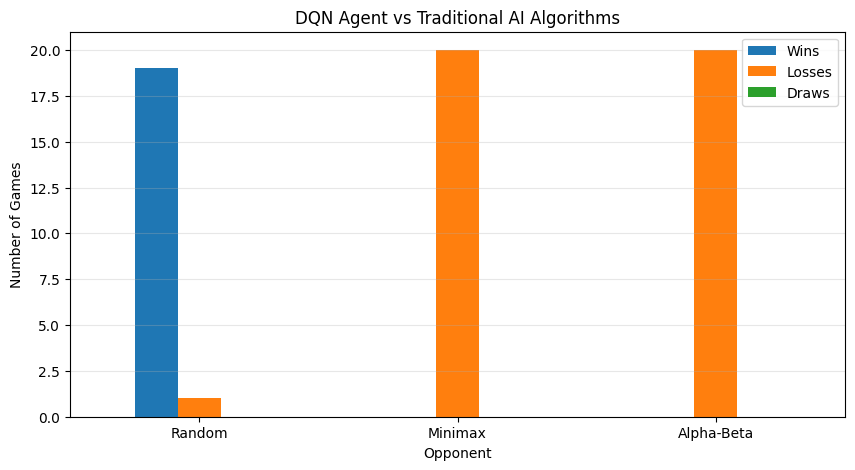

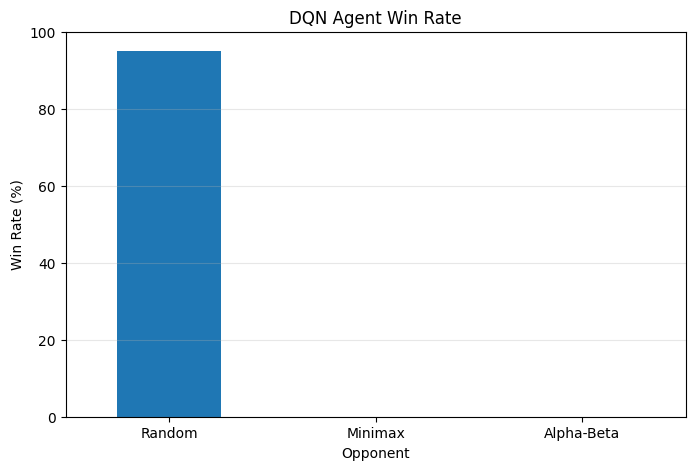

RL model saved successfully!
Files:
- four_in_a_row_dqn.pth
- rl_training_history.csv
- rl_evaluation_results.csv


In [ ]:

# ============================================
# Cell 22: RL Performance Analysis and Saving
# ============================================

# Plot RL vs other algorithms
rl_evaluation.set_index("Opponent")[
    ["Wins", "Losses", "Draws"]
].plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("DQN Agent vs Traditional AI Algorithms")
plt.xlabel("Opponent")
plt.ylabel("Number of Games")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.show()


# Plot win rates
rl_evaluation.set_index("Opponent")[
    "Win Rate (%)"
].plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("DQN Agent Win Rate")
plt.xlabel("Opponent")
plt.ylabel("Win Rate (%)")
plt.ylim(0, 100)
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.show()


# Save trained model
torch.save({
    "model_state_dict": rl_model.state_dict(),
    "target_state_dict": target_model.state_dict(),
    "epsilon": RL_EPSILON,
    "training_steps": training_steps
}, "four_in_a_row_dqn.pth")


# Save training history
rl_history.to_csv(
    "rl_training_history.csv",
    index=False
)

rl_evaluation.to_csv(
    "rl_evaluation_results.csv",
    index=False
)

print("RL model saved successfully!")
print("Files:")
print("- four_in_a_row_dqn.pth")
print("- rl_training_history.csv")
print("- rl_evaluation_results.csv")


In [ ]:

# ============================================
# Cell 23: Load Trained RL Model
# ============================================

checkpoint = torch.load(
    "four_in_a_row_dqn.pth",
    map_location=device,
    weights_only=True
)

rl_model.load_state_dict(
    checkpoint["model_state_dict"]
)

target_model.load_state_dict(
    checkpoint["target_state_dict"]
)

RL_EPSILON = checkpoint["epsilon"]
training_steps = checkpoint["training_steps"]

rl_model.eval()

print("Trained RL model loaded!")
print("Training steps:", training_steps)
print("Current epsilon:", RL_EPSILON)


# Test the loaded model
test_board = create_board()

print("RL selected column:",
      get_rl_action(test_board, AI, epsilon=0))


Trained RL model loaded!
Training steps: 9994
Current epsilon: 0.0820336944319021
RL selected column: 3


In [ ]:

# ============================================================
# FIX: CONSISTENT DQN STATE ENCODING
# ============================================================

def encode_state(board, current_player):

    board_array = np.asarray(board)

    # Convert board to current player's perspective.
    state = np.zeros((6, 7), dtype=np.float32)

    state[board_array == current_player] = 1.0

    opponent = PLAYER if current_player == AI else AI
    state[board_array == opponent] = -1.0

    # Always return exactly 42 values.
    return state.flatten()


# Remove old experiences with potentially inconsistent shapes.
replay_memory.clear()

print("State encoding fixed.")
print("Expected state shape:", encode_state(create_board(), AI).shape)
print("Replay memory cleared:", len(replay_memory))


In [ ]:

# ============================================================
# DQN TRAINING AGAINST RANDOM, MINIMAX AND ALPHA-BETA
# ============================================================

import random
import numpy as np
import pandas as pd
import torch

print("=" * 65)
print(" DQN OPPONENT-BASED REINFORCEMENT LEARNING")
print("=" * 65)

# Training configuration
OPPONENT_EPISODES = 3000
OPPONENTS = ["Random", "Minimax", "Alpha-Beta"]

OPP_EPSILON = 0.50
OPP_EPSILON_MIN = 0.10
OPP_EPSILON_DECAY = 0.9997

OPP_BATCH_SIZE = 64
OPP_DEPTH = 4

# Restore the original self-play model before corrected fine-tuning.
# This avoids continuing from weights updated with the old opponent-target bug.
from pathlib import Path

baseline_checkpoint = Path("four_in_a_row_dqn.pth")

if baseline_checkpoint.exists():
    checkpoint = torch.load(
        baseline_checkpoint,
        map_location=device,
        weights_only=True
    )
    rl_model.load_state_dict(checkpoint["model_state_dict"])
    target_model.load_state_dict(checkpoint["target_state_dict"])
    training_steps = checkpoint["training_steps"]
    print("Restored original self-play checkpoint.")
else:
    print(
        "WARNING: four_in_a_row_dqn.pth was not found. "
        "Continuing from the model currently in memory."
    )

# Start with clean experiences for the corrected opponent-based targets.
replay_memory.clear()

opponent_training_steps = 0
opponent_history = []

opponent_results = {
    name: {"wins": 0, "losses": 0, "draws": 0}
    for name in OPPONENTS
}

print("Episodes:", OPPONENT_EPISODES)
print("Opponents:", OPPONENTS)
print("Initial epsilon:", OPP_EPSILON)
print("Search depth:", OPP_DEPTH)
print("=" * 65)



def play_against_opponent(algorithm, rl_piece, epsilon):

    board = create_board()

    opponent_piece = PLAYER if rl_piece == AI else AI

    # PLAYER always makes the first move.
    current_player = PLAYER

    pending_state = None
    pending_action = None

    while True:

        # ------------------------------------------------
        # RL AGENT TURN
        # ------------------------------------------------
        if current_player == rl_piece:

            state = encode_state(board, rl_piece)

            action = get_rl_action(
                board,
                rl_piece,
                epsilon
            )

            row = get_next_open_row(board, action)

            if row is None:
                raise RuntimeError("Invalid RL action.")

            drop_piece(board, row, action, rl_piece)

            # RL wins
            if winning_move(board, rl_piece):

                store_experience(
                    state,
                    action,
                    1.0,
                    encode_state(board, rl_piece),
                    True
                )

                return "Win"

            # Draw
            if is_draw(board):

                store_experience(
                    state,
                    action,
                    0.0,
                    encode_state(board, rl_piece),
                    True
                )

                return "Draw"

            # Save RL action until opponent responds.
            pending_state = state
            pending_action = action

            current_player = opponent_piece

        # ------------------------------------------------
        # OPPONENT TURN
        # ------------------------------------------------
        else:

            opponent_move = get_experimental_move(
                board,
                opponent_piece,
                algorithm,
                depth=OPP_DEPTH
            )

            opponent_column = opponent_move["column"]

            row = get_next_open_row(board, opponent_column)

            if row is None:
                raise RuntimeError("Invalid opponent action.")

            drop_piece(
                board,
                row,
                opponent_column,
                opponent_piece
            )

            # Opponent wins.
            if winning_move(board, opponent_piece):

                # Save a loss only if RL has actually played.
                if pending_state is not None:

                    store_experience(
                        pending_state,
                        pending_action,
                        -1.0,
                        encode_state(board, rl_piece),
                        True
                    )

                return "Loss"

            # Draw.
            if is_draw(board):

                if pending_state is not None:

                    store_experience(
                        pending_state,
                        pending_action,
                        0.0,
                        encode_state(board, rl_piece),
                        True
                    )

                return "Draw"

            # Save transition only when an RL action exists.
            if pending_state is not None:

                store_experience(
                    pending_state,
                    pending_action,
                    0.0,
                    encode_state(board, rl_piece),
                    False
                )

                pending_state = None
                pending_action = None

            current_player = rl_piece


# ============================================================
# OPPONENT-BASED DQN UPDATE
# The next state is encoded from the RL agent's perspective.
# Therefore, use the standard positive bootstrap target.
# ============================================================

def train_dqn_opponent():

    global training_steps

    if len(replay_memory) < RL_BATCH_SIZE:
        return None

    batch = random.sample(replay_memory, RL_BATCH_SIZE)

    states, actions, rewards, next_states, dones = zip(*batch)

    # Enforce a consistent 42-value state shape.
    states = torch.as_tensor(
        np.stack([np.asarray(s, dtype=np.float32).reshape(42) for s in states]),
        dtype=torch.float32,
        device=device
    )

    actions = torch.as_tensor(
        actions, dtype=torch.long, device=device
    ).unsqueeze(1)

    rewards = torch.as_tensor(
        rewards, dtype=torch.float32, device=device
    )

    next_states = torch.as_tensor(
        np.stack([np.asarray(s, dtype=np.float32).reshape(42) for s in next_states]),
        dtype=torch.float32,
        device=device
    )

    dones = torch.as_tensor(
        dones, dtype=torch.float32, device=device
    )

    current_q = rl_model(states).gather(1, actions).squeeze(1)

    with torch.no_grad():
        next_q = target_model(next_states)
        max_next_q = next_q.max(dim=1)[0]

        # Same RL-player perspective in state and next_state:
        # do NOT negate the next-state Q-value.
        target_q = rewards + (
            RL_GAMMA * max_next_q * (1 - dones)
        )

    loss = loss_function(current_q, target_q)

    optimizer.zero_grad()
    loss.backward()

    torch.nn.utils.clip_grad_norm_(rl_model.parameters(), 1.0)
    optimizer.step()

    training_steps += 1

    if training_steps % RL_TARGET_UPDATE == 0:
        target_model.load_state_dict(rl_model.state_dict())

    return loss.item()


# ============================================================
# TRAINING LOOP
# ============================================================

for episode in range(1, OPPONENT_EPISODES + 1):

    # Rotate opponents equally.
    opponent = OPPONENTS[(episode - 1) % len(OPPONENTS)]

    # Alternate RL agent's starting position.
    rl_piece = AI if episode % 2 == 1 else PLAYER

    # Play one game.
    outcome = play_against_opponent(
        opponent,
        rl_piece,
        OPP_EPSILON
    )

    opponent_results[opponent][
        "wins" if outcome == "Win"
        else "losses" if outcome == "Loss"
        else "draws"
    ] += 1

    # Train using collected experiences.
    loss = train_dqn_opponent()

    if loss is not None:
        try:
            loss_value = float(loss)
        except (TypeError, ValueError):
            loss_value = 0.0
    else:
        loss_value = 0.0

    # Decay exploration.
    OPP_EPSILON = max(
        OPP_EPSILON_MIN,
        OPP_EPSILON * OPP_EPSILON_DECAY
    )

    opponent_history.append({
        "Episode": episode,
        "Opponent": opponent,
        "RL Position": "First" if rl_piece == PLAYER else "Second",
        "Outcome": outcome,
        "Epsilon": OPP_EPSILON,
        "Loss": loss_value,
        "Replay Memory": len(replay_memory)
    })

    # Progress report every 100 episodes.
    if episode % 100 == 0:

        print(f"\nEpisode {episode}/{OPPONENT_EPISODES}")

        for name in OPPONENTS:

            results = opponent_results[name]

            total = sum(results.values())

            win_rate = (
                results["wins"] / total * 100
                if total else 0
            )

            print(
                f"{name:12s} | "
                f"Wins: {results['wins']:4d} | "
                f"Losses: {results['losses']:4d} | "
                f"Draws: {results['draws']:4d} | "
                f"Win Rate: {win_rate:.1f}%"
            )

        print(
            f"Epsilon: {OPP_EPSILON:.4f} | "
            f"Loss: {loss_value:.5f} | "
            f"Memory: {len(replay_memory)}"
        )


# ============================================================
# TRAINING COMPLETED
# ============================================================

opponent_training_history = pd.DataFrame(opponent_history)

print("\n" + "=" * 65)
print(" OPPONENT-BASED TRAINING COMPLETED")
print("=" * 65)

for name in OPPONENTS:

    results = opponent_results[name]
    total = sum(results.values())

    print(f"\n{name}")

    print("Wins:", results["wins"])
    print("Losses:", results["losses"])
    print("Draws:", results["draws"])

    print(
        "Win Rate:",
        round(results["wins"] / total * 100, 2),
        "%"
    )

print("\nFinal epsilon:", round(OPP_EPSILON, 4))
print("Replay memory:", len(replay_memory))
print("=" * 65)

display(opponent_training_history.tail(10))


In [ ]:

# ============================================================
# OPPONENT-BASED TRAINING ANALYSIS
# ============================================================

import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, opponent in enumerate(OPPONENTS):

    data = opponent_training_history[
        opponent_training_history["Opponent"] == opponent
    ].copy()

    window = 50

    wins = (
        data["Outcome"] == "Win"
    ).astype(int)

    rolling_win_rate = wins.rolling(
        window=window,
        min_periods=1
    ).mean() * 100

    axes[i].plot(
        data["Episode"],
        rolling_win_rate
    )

    axes[i].set_title(f"Win Rate vs {opponent}")
    axes[i].set_xlabel("Episode")
    axes[i].set_ylabel("Win Rate (%)")
    axes[i].set_ylim(0, 100)
    axes[i].grid(True)

plt.tight_layout()
plt.show()


# Loss over training
plt.figure(figsize=(10, 5))

plt.plot(
    opponent_training_history["Episode"],
    opponent_training_history["Loss"],
    alpha=0.7
)

plt.title("DQN Training Loss Against Opponents")
plt.xlabel("Episode")
plt.ylabel("Loss")
plt.grid(True)
plt.show()


# Save updated model and training history
torch.save({
    "model_state_dict": rl_model.state_dict(),
    "target_state_dict": target_model.state_dict(),
    "epsilon": OPP_EPSILON,
    "training_steps": training_steps
}, "four_in_a_row_dqn_opponent_trained.pth")

opponent_training_history.to_csv(
    "opponent_training_history.csv",
    index=False
)

print("Updated model saved successfully.")
print("Training history saved successfully.")
